# 03 · Sequências temporais + LSTM no SAML-D — versão 2 (diagnóstico + ablação justa)

Experimento **separado** (não sobrescreve `analysis.ipynb`, `model_completo.ipynb` nem `model_lstm_claude.ipynb`).

> **Hipótese H1 (original).** O histórico recente de transações de uma mesma conta remetente fornece contexto que ajuda a decidir
> se a transação atual é suspeita, além dos atributos da transação isolada.

É uma hipótese **a testar**. Se a LSTM ficar abaixo do LightGBM, o resultado continua válido desde que a metodologia esteja correta.

### Como ler este notebook
| Marca | Significado |
|---|---|
| ✅ **Confirmado** | consta nos arquivos (`SAML-D.md`, saídas do `model_lstm_claude.ipynb`) |
| 🧠 **Decisão/hipótese** | escolha de modelagem a defender e testar |
| ❓ **Verificar** | o notebook confere nos dados antes de usar |

---
## 0. De onde viemos: o que o experimento anterior mostrou (✅ lido nas saídas de `model_lstm_claude.ipynb`)

| Fato observado (dados reais, GPU) | Valor |
|---|---|
| Teste, LSTM `sampler_ponderado`, L=10 (limiar da validação) | precisão 0,288 · recall 0,387 · F1 0,330 · **AP 0,2855** |
| Teste, LightGBM (`SAML-D.md`) | precisão 0,901 · recall 0,836 · F1 0,867 · **AP 0,920** |
| AP na validação por L (`sampler_ponderado`) | L=1: 0,013 · L=5: 0,208 · **L=10: 0,275** · L=20: 0,233 |
| Épocas | quase todos os treinos terminaram no **limite de 6 épocas**, sem *early stopping*; no `baseline` o AP de monitoramento ainda subia a cada época (0,002 → 0,107) |
| Remetentes distintos / transações por remetente | 292.715 contas; mediana 12; p95 = 233; máx. 754 |
| Timestamps repetidos | 18,42 % globalmente; 3.387 pares (mesmo remetente, mesmo timestamp) |

### O que isso sugere (🧠 hipóteses — **não** conclusões)
* **H2 — informação.** A LSTM anterior só via, em cada passo, atributos *da própria transação do remetente*. Ela **não** via
  se o **destinatário** é novo para aquela conta, quantos destinatários distintos a conta já usou, nem a popularidade do destinatário.
  Os modelos de árvore receberam agregados "só passado" (os nomes `envios_anteriores_log`, `pares_anteriores_log` aparecem citados
  no notebook anterior; ❓ não pude abrir o `model_completo.ipynb` para confirmar a lista completa).
  Se H2 for verdadeira, dar **os mesmos agregados** à LSTM deve reduzir boa parte da distância.
* **H3 — subtreino.** 6 épocas com AP ainda subindo indicam que a rede pode estar subtreinada, e não que a arquitetura seja o limite.
* **H1′ — a pergunta que sobra.** Com a informação igualada, **a sequência (L>1) acrescenta algo além dos agregados?**
  Isso exige comparar L=1 × L>1 *com os mesmos atributos* e também contra a árvore com os mesmos atributos.

### O que este notebook faz de diferente (🧠)
1. **Dois conjuntos de atributos por passo**: `base` (10, como antes) e `hist` (+9 agregados *somente do passado*, calculados por passo).
2. **Escada de ablação** (tudo escolhido na validação): `base` × `hist` × `L ∈ {1, 5, 10, 20}`.
3. **Cabeça com conexão direta ao passo atual** (`USAR_SKIP`): assim `L=1` equivale a um MLP nos atributos atuais e a comparação L=1 × L>1 é justa.
4. **Treino mais longo** (até 20 épocas, paciência 4) e monitor de validação maior (reduz o ruído do *early stopping*).
5. **Baselines tabulares retreinados aqui** (GBM sem/com agregados e Regressão Logística) com **os mesmos alvos, a mesma amostra, as mesmas
   features do último passo e o mesmo critério de limiar** — além dos números transcritos do `SAML-D.md`.
6. **Várias sementes** para as configurações finalistas (média ± desvio) e métricas do teste em **4 blocos cronológicos**.
7. **Teste lacrado**: tudo é congelado antes; o teste é avaliado **uma vez**.

### Estado de validação deste arquivo
A lógica de janelas, de atributos históricos, os testes anti-vazamento, os baselines tabulares e os gráficos foram executados com dados **sintéticos**
em um ambiente sem PyTorch/GPU. As células de treino da LSTM seguem os mesmos padrões do notebook anterior (que rodou), mas **esta versão ainda
não foi executada no SAML-D real**: os números finais só existem depois que você rodar.

## 1. Importações e configuração

In [1]:
import copy
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import sparse

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_recall_curve, precision_score, recall_score,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import (BatchSampler, DataLoader, Dataset, RandomSampler, SequentialSampler,
                              WeightedRandomSampler)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ------------------------------ configuração --------------------------------
CAMINHO_CSV = "SAML-D.csv"
PERFIL = "completo"          # "rapido" = teste de fumaça (primeiras 1,5 M transações); "completo" = dataset inteiro

PERFIS = {
    "rapido":   dict(NROWS_DEV=1_500_000, N_TREINO_NATURAL=60_000, N_NEG_UNDER=40_000, AMOSTRAS_POR_EPOCA=60_000,
                     MAX_VAL_EPOCA=100_000, EPOCAS=3, PACIENCIA=2, SEMENTES=[42, 43], TAMANHOS=[1, 5, 10]),
    "completo": dict(NROWS_DEV=None, N_TREINO_NATURAL=500_000, N_NEG_UNDER=150_000, AMOSTRAS_POR_EPOCA=300_000,
                     MAX_VAL_EPOCA=400_000, EPOCAS=20, PACIENCIA=4, SEMENTES=[42, 43, 44], TAMANHOS=[1, 5, 10, 20]),
}
_p = PERFIS[PERFIL]
NROWS_DEV, N_TREINO_NATURAL, N_NEG_UNDER = _p["NROWS_DEV"], _p["N_TREINO_NATURAL"], _p["N_NEG_UNDER"]
AMOSTRAS_POR_EPOCA, MAX_VAL_EPOCA = _p["AMOSTRAS_POR_EPOCA"], _p["MAX_VAL_EPOCA"]
EPOCAS, PACIENCIA, SEMENTES, TAMANHOS = _p["EPOCAS"], _p["PACIENCIA"], _p["SEMENTES"], _p["TAMANHOS"]

SEMENTE = SEMENTES[0]
ALVO = "Is_laundering"
ENTIDADE = "Sender_account"        # 🧠 entidade que agrupa as sequências (justificada na seção 4)
PROP_TREINO, PROP_VAL = 0.70, 0.15
TAMANHO_REF = 10                   # 🧠 L usado para comparar estratégias de balanceamento (Experimento A)

# --- rede / treino
HIDDEN, N_CAMADAS, DROPOUT, EMB_DIM = 64, 1, 0.2, 4
USAR_SKIP = True                   # 🧠 cabeça recebe [h_último ; x_último] (ver seção 10)
LR = 1e-3
BATCH_TREINO, BATCH_AVAL = 512, 8192

np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
DISPOSITIVO = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
    else "cpu"
)
print(f"Perfil: {PERFIL} | dispositivo: {DISPOSITIVO} | torch {torch.__version__}")
print(f"Épocas ≤ {EPOCAS} (paciência {PACIENCIA}) | sementes {SEMENTES} | tamanhos {TAMANHOS}")

Perfil: completo | dispositivo: cuda | torch 2.14.0+cu126
Épocas ≤ 20 (paciência 4) | sementes [42, 43, 44] | tamanhos [1, 5, 10, 20]


## 2. Leitura e inspeção dos dados

* `Laundering_type` **não é lida**: descreve o tipo de lavagem e só é conhecida depois do fato → vazamento direto do alvo.
* `Date` + `Time` → `Timestamp`; ordenação **estável** por `Timestamp` + `reset_index`. Assim o índice `0…N-1` é a posição cronológica
  e as partições coincidem com as dos modelos de árvore (mesmos alvos).
* O ID das contas é lido como `int64` (os IDs têm 10 dígitos) — evita `float` e perda de precisão.

In [2]:
COLUNAS_LEITURA = ["Time", "Date", "Sender_account", "Receiver_account", "Amount", "Payment_currency",
                   "Received_currency", "Sender_bank_location", "Receiver_bank_location", "Payment_type", "Is_laundering"]


def montar_timestamp(df):
    texto = df["Date"].astype(str) + " " + df["Time"].astype(str)
    ts = pd.to_datetime(texto, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    if ts.isna().mean() > 0.5:                      # formato diferente do esperado: deixa o pandas inferir
        ts = pd.to_datetime(texto, errors="coerce")
    return ts


dataset = pd.read_csv(CAMINHO_CSV, usecols=COLUNAS_LEITURA, nrows=NROWS_DEV,
                      dtype={"Sender_account": "int64", "Receiver_account": "int64", "Is_laundering": "int8"})
dataset["Timestamp"] = montar_timestamp(dataset)

n_invalidos = int(dataset["Timestamp"].isna().sum())
n_fora_de_ordem = int((dataset["Timestamp"].diff().dt.total_seconds() < 0).sum())     # ANTES de ordenar
print("Timestamps inválidos:", n_invalidos)
print("Transições fora de ordem no arquivo original:", n_fora_de_ordem, "(0 = já vinha cronológico; ordenamos mesmo assim)")

dataset = (dataset.dropna(subset=["Timestamp"]).drop(columns=["Date", "Time"])
           .sort_values("Timestamp", kind="stable").reset_index(drop=True))
N = len(dataset)
print("\nDimensões:", dataset.shape, f"| positivas: {int(dataset[ALVO].sum())} ({dataset[ALVO].mean():.4%})")
print("Período:", dataset["Timestamp"].min(), "→", dataset["Timestamp"].max())
if NROWS_DEV is None:
    print("Conferência com o SAML-D.md (9.504.852 linhas · 9.873 positivas):",
          "✅ igual" if (N == 9_504_852 and int(dataset[ALVO].sum()) == 9_873) else "⚠️ DIFERENTE")
display(dataset.head())

Timestamps inválidos: 0
Transições fora de ordem no arquivo original: 0 (0 = já vinha cronológico; ordenamos mesmo assim)

Dimensões: (9504852, 10) | positivas: 9873 (0.1039%)
Período: 2022-10-07 10:35:19 → 2023-08-23 10:57:12
Conferência com o SAML-D.md (9.504.852 linhas · 9.873 positivas): ✅ igual


,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Timestamp
0,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,2022-10-07 10:35:19
1,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,2022-10-07 10:35:20
2,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,2022-10-07 10:35:20
3,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,2022-10-07 10:35:21
4,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,2022-10-07 10:35:21


## 3. Auditoria de timestamps, IDs e alvo (❓ → verificado)

1. **Alvo** só 0/1, sem ausentes. 2. **Amount** não negativo (usamos `log1p`). 3. **Timestamps repetidos**: transações no mesmo segundo têm ordem relativa
indefinida; mantemos a ordem do arquivo (ordenação estável) e medimos quantos casos afetam *a mesma conta*.
4. **ID da conta utilizável?** Quantas contas, quantas transações por conta, e o remetente também aparece como destinatário?

> ⚠️ **IDs de conta NÃO entram como atributo.** Só servem para *agrupar* o histórico. Usar o ID como atributo permitiria memorizar contas (atalho artificial).

In [3]:
print("Valores do alvo:", dataset[ALVO].value_counts(dropna=False).to_dict())
print("Ausentes por coluna:\n", dataset.isna().sum().to_string(), "\n")
assert set(dataset[ALVO].unique()) <= {0, 1}, "alvo deve ser 0/1"
print(f"Amount: mín={dataset['Amount'].min():,.2f} | mediana={dataset['Amount'].median():,.2f} | máx={dataset['Amount'].max():,.2f} "
      f"| valores ≤ 0: {int((dataset['Amount'] <= 0).sum())}")
assert dataset["Amount"].min() > -1, "log1p exige Amount > -1"

ts = dataset["Timestamp"]
print(f"\nTimestamps repetidos (global): {ts.duplicated().sum():,} ({ts.duplicated().mean():.2%})")
print(f"Mesmo remetente + mesmo timestamp: {dataset.duplicated([ENTIDADE, 'Timestamp']).sum():,}")

contagem = dataset.groupby(ENTIDADE).size()
print(f"\nContas remetentes distintas: {len(contagem):,} | destinatárias distintas: {dataset['Receiver_account'].nunique():,}")
print(f"Remetentes que também aparecem como destinatárias: {contagem.index.isin(dataset['Receiver_account'].unique()).mean():.1%}")
display(contagem.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1).to_frame("transações por remetente"))
pos_por_conta = dataset.groupby(ENTIDADE)[ALVO].sum()
print(f"Contas com ≥1 transação positiva: {(pos_por_conta > 0).sum():,} ({(pos_por_conta > 0).mean():.2%} das contas)")

Valores do alvo: {0: 9494979, 1: 9873}
Ausentes por coluna:
 Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Timestamp                 0 

Amount: mín=3.73 | mediana=6,113.72 | máx=12,618,498.40 | valores ≤ 0: 0

Timestamps repetidos (global): 1,750,941 (18.42%)
Mesmo remetente + mesmo timestamp: 3,387

Contas remetentes distintas: 292,715 | destinatárias distintas: 652,266
Remetentes que também aparecem como destinatárias: 30.6%


,transações por remetente
count,292715.0
mean,32.5
std,91.6
min,1.0
25%,9.0
50%,12.0
75%,12.0
90%,14.0
95%,233.0
99%,506.0


Contas com ≥1 transação positiva: 4,950 (1.69% das contas)


## 4. Definição da sequência (🧠 decisões que você deve saber defender)

**Entidade.** `Sender_account`. *Por quê:* captura o **comportamento de envio** da conta. Misturar contas numa sequência criaria histórico artificial.
Alternativas para trabalho futuro (não testadas aqui): histórico por conta **destinatária** ou por par remetente→destinatário.

**Rótulo.** Cada exemplo é uma **transação-alvo** `T(t)`. Entrada = as últimas `L` transações **da mesma conta, até `T(t)` inclusive**.
Alvo = `Is_laundering` de `T(t)` — *não* "qualquer positivo na janela".

```
conta A:   T1   T2   T3   T4   T5   T6   T7 ...
L = 5      └────────────────┘            alvo = T5   (entrada [T1..T5])
              └────────────────┘         alvo = T6   (entrada [T2..T6])
```

**Stride 1 / todo registro é alvo uma vez.** Mesmos alvos dos modelos de árvore (1.425.728 no teste). As janelas se sobrepõem no *contexto*, mas
**o mesmo registro-alvo nunca está em duas partições**.

**Histórico curto.** Se a conta tem menos de `L-1` transações anteriores, preenchemos com **zeros à esquerda** + canal `mascara` (1 = real, 0 = preenchimento).

**O histórico pode atravessar partições?** Sim, **só para trás no tempo** (no mundo real esse histórico existiria). Proibido: informação **futura** e **rótulos**
(nem o `Is_laundering` do histórico entra: em produção o rótulo só chega após investigação).

### Atributos por passo (todos "somente passado")
**`base` (10):** `Amount_log`, `dia_mes`, `hora_sin/cos`, `semana_sin/cos`, `operacao_internacional`, `mudanca_moeda`, `dt_log` (tempo desde o envio anterior da conta), `sem_anterior`.

**`hist` (+9, 🧠 novos nesta versão)** — resumem **todo** o passado da conta até aquele passo, não só os `L` últimos:

| Atributo | O que mede | Padrão de lavagem que poderia refletir (🧠 hipótese) |
|---|---|---|
| `env_prev_log` | nº de envios anteriores do remetente | conta nova × antiga |
| `valor_medio_prev_log` | valor médio dos envios anteriores | nível habitual da conta |
| `razao_valor_media` | valor atual ÷ média anterior (em log) | salto de valor |
| `pares_prev_log` | nº de envios anteriores para **este mesmo destinatário** | relação recorrente |
| `receptor_novo` | 1 se é o primeiro envio para este destinatário | mudança de destinatário |
| `receptores_distintos_prev_log` | destinatários distintos já usados pelo remetente | espalhamento (*fan-out*) |
| `rec_recebimentos_prev_log` | nº de recebimentos anteriores do destinatário | popularidade do destinatário |
| `rec_remetentes_distintos_prev_log` | remetentes distintos que já enviaram a este destinatário | concentração (*fan-in*) |
| `rem_recebimentos_prev_log` | quantas vezes o **remetente** já foi destinatário | conta que também recebe (30,6 % dos remetentes) |

> Esses nomes de padrão são **hipóteses de interpretação**; importância de atributo não é causalidade nem prova de lavagem.
> Os IDs usados para calcular as contagens **não** viram atributos.

## 5. Divisão temporal (definida **antes** de qualquer ajuste de transformação)

Mesma regra do `model_completo.ipynb`: `int(N·0,70)` e `int(N·0,85)` sobre os dados **ordenados no tempo**. O índice já é a posição cronológica,
então os alvos de cada partição são intervalos de índices.

In [4]:
i_tr, i_val = int(N * PROP_TREINO), int(N * (PROP_TREINO + PROP_VAL))
alvos_treino = np.arange(0, i_tr, dtype=np.int64)
alvos_val = np.arange(i_tr, i_val, dtype=np.int64)
alvos_teste = np.arange(i_val, N, dtype=np.int64)

y_all = dataset[ALVO].to_numpy(dtype=np.int8)
resumo_part = pd.DataFrame({
    "alvos": [len(a) for a in (alvos_treino, alvos_val, alvos_teste)],
    "positivos": [int(y_all[a].sum()) for a in (alvos_treino, alvos_val, alvos_teste)],
    "início": [dataset["Timestamp"].iloc[a[0]] for a in (alvos_treino, alvos_val, alvos_teste)],
    "fim": [dataset["Timestamp"].iloc[a[-1]] for a in (alvos_treino, alvos_val, alvos_teste)],
}, index=["Treino", "Validação", "Teste"])
resumo_part["taxa_%"] = resumo_part["positivos"] / resumo_part["alvos"] * 100
display(resumo_part)

REGISTRADO = {"Treino": (6_653_396, 6_764), "Validação": (1_425_728, 1_412), "Teste": (1_425_728, 1_697)}
if NROWS_DEV is None:
    for nome, (n_reg, p_reg) in REGISTRADO.items():
        ok = (resumo_part.loc[nome, "alvos"] == n_reg) and (resumo_part.loc[nome, "positivos"] == p_reg)
        print(f"{nome:<10s} {'✅ igual ao SAML-D.md' if ok else '⚠️ DIFERENTE do SAML-D.md'}  ({n_reg:,} / {p_reg:,})")
else:
    print("Perfil rápido: partições diferem das registradas (só as primeiras linhas no tempo); comparação com o SAML-D.md ignorada.")

,alvos,positivos,início,fim,taxa_%
Treino,6653396,6764,2022-10-07 10:35:19,2023-05-18 19:28:03,0.101662
Validação,1425728,1412,2023-05-18 19:28:03,2023-07-05 15:24:39,0.099037
Teste,1425728,1697,2023-07-05 15:24:42,2023-08-23 10:57:12,0.119027


Treino     ✅ igual ao SAML-D.md  (6,653,396 / 6,764)
Validação  ✅ igual ao SAML-D.md  (1,425,728 / 1,412)
Teste      ✅ igual ao SAML-D.md  (1,425,728 / 1,697)


## 6. Pré-processamento (ajustado **somente** no treino)

* **Códigos de conta**: `Sender_account` e `Receiver_account` são codificados em um vocabulário comum (inteiros `0…M-1`) só para contar eventos rapidamente.
  Os códigos **não** são atributos.
* **Atributos `hist`**: cada um usa apenas linhas com índice **menor** (passado) — ver `contagem_recebimentos_previos` (busca binária vetorizada, sem *loop*)
  e as funções `cumcount`/`cumsum_previo`. Observação: transações no **mesmo segundo** são ordenadas pela ordem do arquivo; a "mais antiga" do empate é a de menor índice (❓ limitação declarada).
* `StandardScaler`: `fit` **apenas** nas linhas de treino `[0, i_tr)`, `transform` em todas.
* Categóricas → **códigos inteiros** com vocabulário do treino. Categoria nunca vista no treino → `0`. O código `0` também é o preenchimento:
  `Embedding(padding_idx=0)` mantém esse vetor em zero.
* Guardamos **uma linha por transação** (`F_num`, `F_cat`) e montamos as janelas **sob demanda** (seção 7); materializar todas custaria `N·L·d·4` bytes (≈ 12 GB para L=20, medido no notebook anterior).
* **Diferença para as árvores:** One-Hot lá, **embeddings** aqui (compactos para sequências).

In [5]:
COLUNAS_BASE = ["Amount_log", "dia_mes", "hora_sin", "hora_cos", "semana_sin", "semana_cos",
                "operacao_internacional", "mudanca_moeda", "dt_log", "sem_anterior"]
COLUNAS_HIST = ["env_prev_log", "valor_medio_prev_log", "razao_valor_media", "pares_prev_log", "receptor_novo",
                "receptores_distintos_prev_log", "rec_recebimentos_prev_log", "rec_remetentes_distintos_prev_log",
                "rem_recebimentos_prev_log"]
COLUNAS_CAT = ["Payment_type", "Payment_currency", "Received_currency", "Sender_bank_location", "Receiver_bank_location"]
K_POR_CONJUNTO = {"base": len(COLUNAS_BASE), "hist": len(COLUNAS_BASE) + len(COLUNAS_HIST)}   # nº de colunas numéricas por passo
assert ALVO not in COLUNAS_BASE + COLUNAS_HIST + COLUNAS_CAT, "o alvo não pode ser atributo!"


def codigos_de_conta(df):
    # vocabulário comum a remetentes e destinatários -> códigos 0..M-1 (só para contar; NÃO são atributos)
    n = len(df)
    todos, _ = pd.factorize(np.concatenate([df["Sender_account"].to_numpy(), df["Receiver_account"].to_numpy()]))
    return todos[:n].astype(np.int64), todos[n:].astype(np.int64)


def cumcount(chave):
    # nº de linhas ANTERIORES com a mesma chave (0 = primeira ocorrência). Exige dados em ordem cronológica.
    return pd.Series(chave).groupby(chave, sort=False).cumcount().to_numpy()


def cumsum_previo(valores, chave):
    # soma dos valores das linhas ANTERIORES com a mesma chave (exclui a linha atual)
    return pd.Series(valores).groupby(chave, sort=False).cumsum().to_numpy() - valores


def contagem_recebimentos_previos(cs, cr):
    # para cada linha i: nº de linhas j < i em que Receiver_j == Sender_i (a conta remetente já atuou como destinatária?)
    n = len(cs)
    idx = np.arange(n, dtype=np.int64)
    chaves_rec = np.sort(cr * n + idx)                                  # (receptor, posição) ordenado
    base = cs * n
    return np.searchsorted(chaves_rec, base + idx, side="left") - np.searchsorted(chaves_rec, base, side="left")


def features_base(df, cs):
    t = df["Timestamp"]
    hora, dow = t.dt.hour.to_numpy(), t.dt.dayofweek.to_numpy()
    dt = t.groupby(cs, sort=False).diff().dt.total_seconds().to_numpy()          # NaN no 1º envio da conta (só passado)
    out = np.empty((len(df), len(COLUNAS_BASE)), dtype=np.float32)
    out[:, 0] = np.log1p(df["Amount"].to_numpy(np.float64))
    out[:, 1] = t.dt.day.to_numpy()
    out[:, 2], out[:, 3] = np.sin(2 * np.pi * hora / 24), np.cos(2 * np.pi * hora / 24)
    out[:, 4], out[:, 5] = np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)
    out[:, 6] = (df["Sender_bank_location"] != df["Receiver_bank_location"]).to_numpy()
    out[:, 7] = (df["Payment_currency"] != df["Received_currency"]).to_numpy()
    out[:, 8] = np.log1p(np.nan_to_num(dt, nan=0.0))
    out[:, 9] = np.isnan(dt)
    return out


def features_hist(df, cs, cr):
    amt = df["Amount"].to_numpy(np.float64)
    n_prev = cumcount(cs).astype(np.float64)                                    # envios anteriores do remetente
    media_prev = np.where(n_prev > 0, np.clip(cumsum_previo(amt, cs), 0, None) / np.maximum(n_prev, 1.0), 0.0)
    razao = np.where(n_prev > 0, np.log1p(amt) - np.log1p(media_prev), 0.0)
    pares_prev = cumcount(cs * (int(cr.max()) + 1) + cr).astype(np.float64)    # envios anteriores do MESMO par
    novo = (pares_prev == 0).astype(np.float64)                                 # 1ª vez que o remetente envia a este destinatário
    out = np.empty((len(df), len(COLUNAS_HIST)), dtype=np.float32)
    out[:, 0] = np.log1p(n_prev)
    out[:, 1] = np.log1p(media_prev)
    out[:, 2] = razao
    out[:, 3] = np.log1p(pares_prev)
    out[:, 4] = novo
    out[:, 5] = np.log1p(cumsum_previo(novo, cs))                               # destinatários distintos já usados pelo remetente
    out[:, 6] = np.log1p(cumcount(cr))                                          # recebimentos anteriores do destinatário
    out[:, 7] = np.log1p(cumsum_previo(novo, cr))                               # remetentes distintos que já enviaram a ele
    out[:, 8] = np.log1p(contagem_recebimentos_previos(cs, cr))                 # o remetente já foi destinatário?
    return out


class ContextoSequencias:
    # Guarda matrizes POR TRANSAÇÃO e monta janelas por conta sem materializá-las.
    def __init__(self, df, i_treino):
        self.N = len(df)
        self.y = df[ALVO].to_numpy(np.int8)
        self.cs, self.cr = codigos_de_conta(df)
        F = np.concatenate([features_base(df, self.cs), features_hist(df, self.cs, self.cr)], axis=1)   # (N, 10+9)
        self.nomes_num = COLUNAS_BASE + COLUNAS_HIST
        self.escalonador = StandardScaler().fit(F[:i_treino])                   # fit SÓ no treino
        self.F_num = self.escalonador.transform(F).astype(np.float32)           # (N, 19)
        del F
        self.vocab = {c: pd.Index(df[c].iloc[:i_treino].unique()) for c in COLUNAS_CAT}                 # vocabulário do treino
        self.F_cat = np.stack([pd.Categorical(df[c], categories=self.vocab[c]).codes.astype(np.int16) + 1
                               for c in COLUNAS_CAT], axis=1)                    # (N, 5)  0 = desconhecida/preenchimento
        self.cardinalidades = [len(self.vocab[c]) + 1 for c in COLUNAS_CAT]
        self.pos_grupo = cumcount(self.cs).astype(np.int64)                     # transações ANTERIORES da conta
        self.order = np.argsort(self.cs, kind="stable")                         # linhas agrupadas por conta, cronológicas
        self.rank = np.empty(self.N, dtype=np.int64)
        self.rank[self.order] = np.arange(self.N)

    def obter_lote(self, idx, L, k):
        # idx: (B,) alvos | L: tamanho | k: nº de colunas numéricas (10 = base, 19 = hist)
        idx = np.asarray(idx, dtype=np.int64)
        desl = np.arange(-L + 1, 1, dtype=np.int64)                              # (L,)  ex.: [-4,-3,-2,-1,0]
        real = (self.pos_grupo[idx][:, None] + desl[None, :]) >= 0              # (B,L) True = transação real da conta
        pos = np.clip(self.rank[idx][:, None] + desl[None, :], 0, self.N - 1)
        linhas = self.order[pos]                                                 # (B,L) índices globais das transações
        Xn = np.where(real[..., None], self.F_num[linhas][..., :k], 0.0).astype(np.float32)     # (B,L,k) zero no preenchimento
        Xn = np.concatenate([Xn, real[..., None].astype(np.float32)], axis=-1)   # (B,L,k+1) + canal máscara
        Xc = np.where(real[..., None], self.F_cat[linhas], 0).astype(np.int64)   # (B,L,5)
        return Xn, Xc, self.y[idx].astype(np.float32), linhas, real              # y: rótulo da ÚLTIMA transação


ctx = ContextoSequencias(dataset, i_tr)
ts_ns = dataset["Timestamp"].to_numpy().astype("datetime64[ns]").astype(np.int64)

print("F_num:", ctx.F_num.shape, ctx.F_num.dtype, f"{ctx.F_num.nbytes / 1e6:,.0f} MB | F_cat:", ctx.F_cat.shape, f"{ctx.F_cat.nbytes / 1e6:,.0f} MB")
print("Cardinalidades (inclui 0 = desconhecida):", dict(zip(COLUNAS_CAT, ctx.cardinalidades)))
print("Categorias do val/teste fora do vocabulário do treino:", {c: int((ctx.F_cat[i_tr:, j] == 0).sum()) for j, c in enumerate(COLUNAS_CAT)})
mem_lazy = (ctx.F_num.nbytes + ctx.F_cat.nbytes + ctx.order.nbytes + ctx.rank.nbytes + ctx.pos_grupo.nbytes) / 1e9
print(f"\nMemória (sob demanda): {mem_lazy:.2f} GB")
for L_ in TAMANHOS:
    print(f"  se materializássemos todas as janelas com L={L_:>2d}: {N * L_ * (K_POR_CONJUNTO['hist'] + 1 + 5) * 4 / 1e9:6.1f} GB")

F_num: (9504852, 19) float32 722 MB | F_cat: (9504852, 5) 95 MB
Cardinalidades (inclui 0 = desconhecida): {'Payment_type': 8, 'Payment_currency': 14, 'Received_currency': 14, 'Sender_bank_location': 19, 'Receiver_bank_location': 19}
Categorias do val/teste fora do vocabulário do treino: {'Payment_type': 0, 'Payment_currency': 0, 'Received_currency': 0, 'Sender_bank_location': 0, 'Receiver_bank_location': 0}

Memória (sob demanda): 1.05 GB
  se materializássemos todas as janelas com L= 1:    1.0 GB
  se materializássemos todas as janelas com L= 5:    4.8 GB
  se materializássemos todas as janelas com L=10:    9.5 GB
  se materializássemos todas as janelas com L=20:   19.0 GB


### 6.1 Verificações de *leakage* e de dimensões (rode **antes** de treinar)

Se qualquer `assert` falhar, **não treine**.

**Janelas**
* a **última** posição de cada janela é a própria transação-alvo; nenhuma linha é **posterior** ao alvo (índice e timestamp);
* todas as linhas reais pertencem à **mesma conta**; nº de passos reais = `min(L, anteriores + 1)`; preenchimento = 0;
* **teste de independência dos rótulos:** inverter todos os `Is_laundering` **não altera** `Xn`/`Xc` (os rótulos do histórico nunca entram);
* **confronto com força bruta:** para alguns alvos, recalculamos a janela *com um filtro simples do pandas/numpy* e comparamos.

**Atributos `hist`**
* para alguns alvos, recalculamos **cada um dos 9 atributos** com contagens ingênuas sobre `linhas[:i]` e comparamos com o valor guardado (após inverter o `StandardScaler`).

**Partições:** disjuntas e em ordem cronológica.

In [6]:
def verificar_sequencias(ctx, alvos, L, k, n=3000, semente=SEMENTE):
    rng = np.random.default_rng(semente)
    idx = rng.choice(alvos, size=min(n, len(alvos)), replace=False)
    Xn, Xc, y, linhas, real = ctx.obter_lote(idx, L, k)
    B = len(idx)
    assert Xn.shape == (B, L, k + 1) and Xc.shape == (B, L, len(COLUNAS_CAT)) and y.shape == (B,)
    assert (linhas[:, -1] == idx).all(), "a última posição deve ser o alvo"
    assert real[:, -1].all(), "o alvo é sempre real"
    assert (linhas[real.nonzero()] <= np.repeat(idx, real.sum(1))).all(), "linha futura na janela (índice)"
    assert (ts_ns[linhas[real]] <= np.repeat(ts_ns[idx], real.sum(1))).all(), "linha futura na janela (timestamp)"
    assert (ctx.cs[linhas[real]] == np.repeat(ctx.cs[idx], real.sum(1))).all(), "janela mistura contas diferentes"
    assert (real.sum(1) == np.minimum(L, ctx.pos_grupo[idx] + 1)).all(), "nº de passos reais incorreto"
    if L > 1:
        ambos = real[:, 1:] & real[:, :-1]
        assert (np.diff(linhas, axis=1)[ambos] > 0).all(), "janela fora de ordem cronológica"
    assert (y == y_all[idx]).all(), "rótulo deve ser o do alvo"
    assert (Xn[~real][:, :-1] == 0).all() and (Xc[~real] == 0).all(), "preenchimento deve ser zero"
    # os rótulos do histórico nunca podem influenciar a entrada
    y_orig = ctx.y
    try:
        ctx.y = (1 - y_orig).astype(np.int8)
        Xn2, Xc2, _, _, _ = ctx.obter_lote(idx, L, k)
    finally:
        ctx.y = y_orig
    assert np.array_equal(Xn, Xn2) and np.array_equal(Xc, Xc2), "a entrada depende dos rótulos!"
    return True


def conferir_janela_forca_bruta(ctx, L, k, alvos, n=25, semente=SEMENTE):
    # reconstrói a janela com um filtro direto "mesma conta e índice <= alvo, últimas L" e compara
    rng = np.random.default_rng(semente)
    for i in rng.choice(alvos, size=min(n, len(alvos)), replace=False):
        esperado = np.flatnonzero(ctx.cs[: i + 1] == ctx.cs[i])[-L:]
        _, _, _, linhas, real = ctx.obter_lote([i], L, k)
        assert np.array_equal(linhas[0][real[0]], esperado), f"janela difere da força bruta (alvo {i})"
    return True


def hist_ingenuo(ctx, df_amount, i):
    # os 9 atributos históricos do alvo i recomputados de forma ingênua usando SÓ as linhas [0, i)
    s, r = ctx.cs[i], ctx.cr[i]
    ant = slice(0, i)
    cs_a, cr_a = ctx.cs[ant], ctx.cr[ant]
    m_s = cs_a == s
    n_prev = int(m_s.sum())
    media = float(df_amount[ant][m_s].mean()) if n_prev > 0 else 0.0
    razao = (np.log1p(df_amount[i]) - np.log1p(media)) if n_prev > 0 else 0.0
    pares = int((m_s & (cr_a == r)).sum())
    return np.array([np.log1p(n_prev), np.log1p(media), razao, np.log1p(pares), float(pares == 0),
                     np.log1p(len(np.unique(cr_a[m_s]))), np.log1p(int((cr_a == r).sum())),
                     np.log1p(len(np.unique(cs_a[cr_a == r]))), np.log1p(int((cr_a == s).sum()))])


def conferir_hist(ctx, alvos, n=40, semente=SEMENTE):
    amount = dataset["Amount"].to_numpy(np.float64)
    rng = np.random.default_rng(semente)
    nb = len(COLUNAS_BASE)
    for i in np.sort(rng.choice(alvos, size=min(n, len(alvos)), replace=False)):
        guardado = ctx.escalonador.inverse_transform(ctx.F_num[[i]])[0, nb:]
        assert np.allclose(guardado, hist_ingenuo(ctx, amount, i), atol=2e-3), \
            f"atributos hist divergem da contagem ingênua no alvo {i}: {guardado} vs {hist_ingenuo(ctx, amount, i)}"
    return True


for L_ in TAMANHOS:
    for conj, k_ in K_POR_CONJUNTO.items():
        for nome, a in [("treino", alvos_treino), ("validação", alvos_val), ("teste", alvos_teste)]:
            verificar_sequencias(ctx, a, L_, k_)
    conferir_janela_forca_bruta(ctx, L_, K_POR_CONJUNTO["hist"], alvos_val)
print("✅ janelas OK (formas, passado apenas, mesma conta, preenchimento, independência dos rótulos, força bruta) para L =", TAMANHOS)

conferir_hist(ctx, alvos_treino); conferir_hist(ctx, alvos_val); conferir_hist(ctx, alvos_teste)
print("✅ os 9 atributos hist coincidem com a contagem ingênua usando só o passado")

assert len(np.intersect1d(alvos_treino, alvos_val)) == 0 and len(np.intersect1d(alvos_val, alvos_teste)) == 0
assert alvos_treino.max() < alvos_val.min() and alvos_val.max() < alvos_teste.min()
assert ts_ns[alvos_treino].max() <= ts_ns[alvos_val].min() and ts_ns[alvos_val].max() <= ts_ns[alvos_teste].min()
print("✅ partições disjuntas e cronológicas (treino < validação < teste)")


def exemplo_sequencia(idx_alvo, L):
    # janela de um alvo em formato legível (para conferir e explicar na banca)
    _, _, _, linhas, real = ctx.obter_lote([idx_alvo], L, K_POR_CONJUNTO["base"])
    linhas = linhas[0][real[0]]
    return dataset.loc[linhas, ["Timestamp", ENTIDADE, "Receiver_account", "Amount", "Payment_type",
                                "Sender_bank_location", "Receiver_bank_location", ALVO]]


candidatos = alvos_val[(y_all[alvos_val] == 1) & (ctx.pos_grupo[alvos_val] >= 6)]
if len(candidatos):
    print(f"\nExemplo (L=6): alvo = última linha (índice {candidatos[0]}). Só a última linha define o rótulo.")
    display(exemplo_sequencia(int(candidatos[0]), 6))

✅ janelas OK (formas, passado apenas, mesma conta, preenchimento, independência dos rótulos, força bruta) para L = [1, 5, 10, 20]
✅ os 9 atributos hist coincidem com a contagem ingênua usando só o passado
✅ partições disjuntas e cronológicas (treino < validação < teste)

Exemplo (L=6): alvo = última linha (índice 6653497). Só a última linha define o rótulo.


,Timestamp,Sender_account,Receiver_account,Amount,Payment_type,Sender_bank_location,Receiver_bank_location,Is_laundering
4162326,2023-02-24 08:02:07,1715501381,2299704124,165.94,Cash Withdrawal,UK,UK,0
5346821,2023-04-04 21:12:12,1715501381,2299704124,190.98,Cash Withdrawal,UK,UK,0
5374107,2023-04-05 19:27:44,1715501381,2299704124,186.62,Cash Withdrawal,UK,UK,0
5461482,2023-04-08 18:27:59,1715501381,2299704124,115.84,Cash Withdrawal,UK,UK,0
6149074,2023-05-01 17:03:53,1715501381,2299704124,214.14,Cash Withdrawal,UK,UK,0
6653497,2023-05-18 19:31:13,1715501381,6919638030,60679.20,Credit card,UK,UK,1


## 7. EDA das sequências

Perguntas:
1. **Classes dos alvos** por partição: a proporção (~0,1 %) muda no teste?
2. **Cobertura de histórico:** que fração dos alvos tem janela completa para cada `L`? Contas com pouco histórico → janela grande é quase só preenchimento.
3. **Positivas têm histórico mais curto ou mais longo que negativas?**
4. **Distribuição temporal** dos positivos (deriva?).
5. **Transações por conta remetente.**
6. **Os atributos `hist` separam as classes?** (diferença padronizada de médias no **treino**; descreve os dados, não prova que o modelo aprenderá).

> Os gráficos descrevem os dados; **não provam** que a LSTM funcionará nem explicam *por que* uma transação é suspeita.

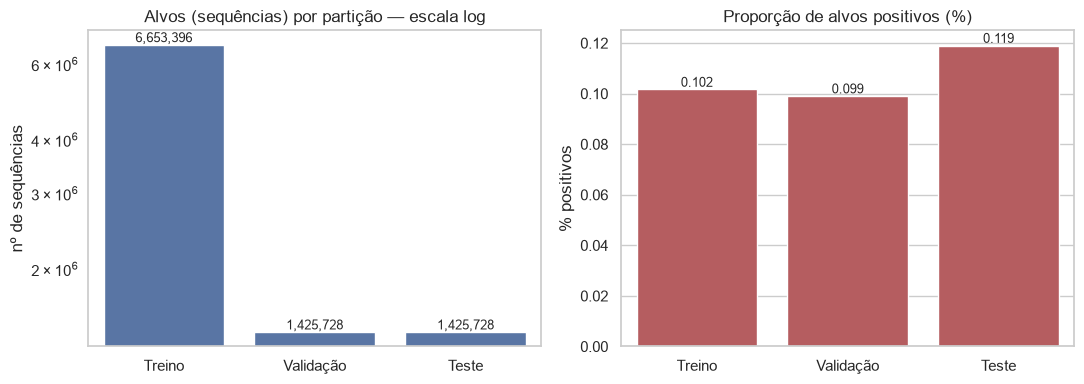

,partição,L,janela_completa_%,positivos_com_janela_completa_%,taxa_positiva_completa_%,taxa_positiva_incompleta_%
0,Treino,1,100.000,100.000,0.102,NaN
1,Treino,5,87.898,75.370,0.087,0.207
2,Treino,10,75.476,60.201,0.081,0.165
3,Treino,20,66.252,45.520,0.070,0.164
4,Validação,1,100.000,100.000,0.099,NaN
5,Validação,5,90.575,96.459,0.105,0.037
6,Validação,10,78.709,87.465,0.110,0.058
7,Validação,20,71.230,69.405,0.096,0.105
8,Teste,1,100.000,100.000,0.119,NaN
9,Teste,5,91.182,96.759,0.126,0.044


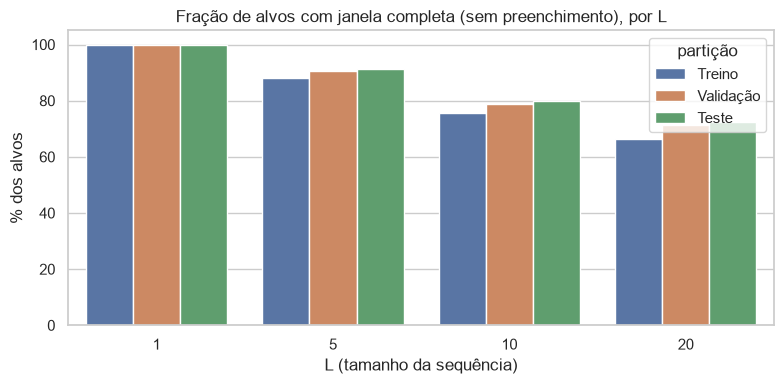

In [7]:
# --- 1) classes por partição
df_ = resumo_part.reset_index().rename(columns={"index": "partição"})
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df_, x="partição", y="alvos", ax=ax[0], color="#4C72B0")
ax[0].set_yscale("log"); ax[0].set_title("Alvos (sequências) por partição — escala log"); ax[0].set_ylabel("nº de sequências"); ax[0].set_xlabel("")
sns.barplot(data=df_, x="partição", y="taxa_%", ax=ax[1], color="#C44E52")
ax[1].set_title("Proporção de alvos positivos (%)"); ax[1].set_ylabel("% positivos"); ax[1].set_xlabel("")
for a, col in zip(ax, ["alvos", "taxa_%"]):
    for p, v in zip(a.patches, df_[col]):
        a.annotate(f"{v:,.3f}" if col == "taxa_%" else f"{int(v):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

# --- 2) cobertura de histórico por L
linhas_ = []
for nome, a in [("Treino", alvos_treino), ("Validação", alvos_val), ("Teste", alvos_teste)]:
    for L_ in TAMANHOS:
        completa = ctx.pos_grupo[a] >= (L_ - 1)
        yy = y_all[a]
        linhas_.append({"partição": nome, "L": L_, "janela_completa_%": completa.mean() * 100,
                        "positivos_com_janela_completa_%": (completa[yy == 1].mean() * 100) if yy.sum() else np.nan,
                        "taxa_positiva_completa_%": (yy[completa].mean() * 100) if completa.any() else np.nan,
                        "taxa_positiva_incompleta_%": (yy[~completa].mean() * 100) if (~completa).any() else np.nan})
cobertura = pd.DataFrame(linhas_)
display(cobertura.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=cobertura, x="L", y="janela_completa_%", hue="partição", ax=ax)
ax.set(title="Fração de alvos com janela completa (sem preenchimento), por L", xlabel="L (tamanho da sequência)", ylabel="% dos alvos")
plt.tight_layout(); plt.show()

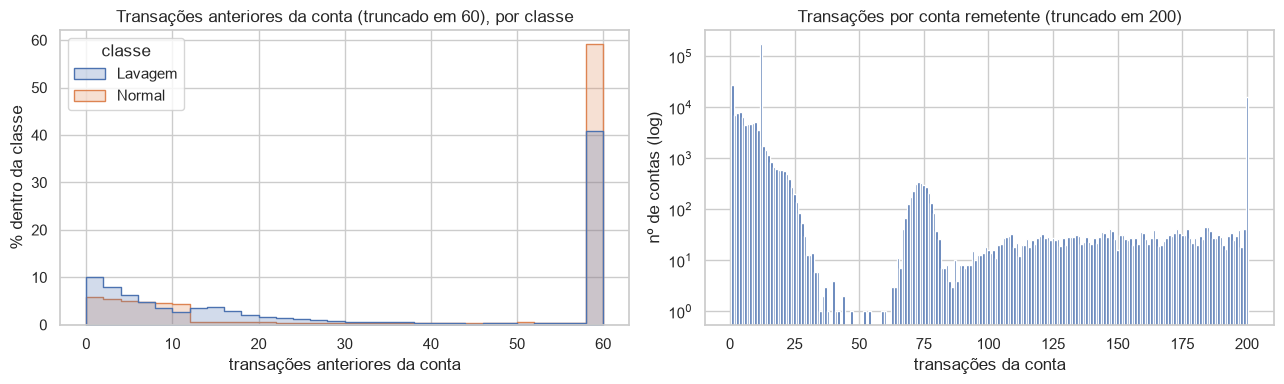

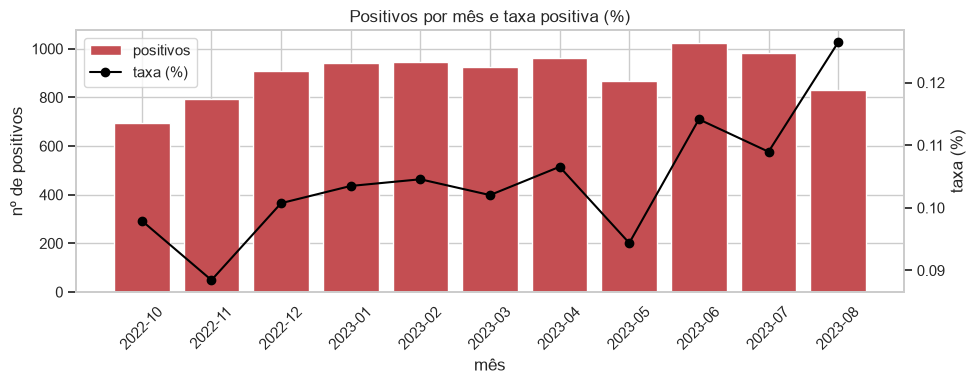

,mes,total,positivos,taxa,taxa_%
0,2022-10,708654,694,0.0010,0.0979
1,2022-11,897621,794,0.0009,0.0885
2,2022-12,900341,907,0.0010,0.1007
3,2023-01,908320,940,0.0010,0.1035
4,2023-02,904806,946,0.0010,0.1046
5,2023-03,908562,927,0.0010,0.1020
6,2023-04,902883,962,0.0011,0.1065
7,2023-05,917601,866,0.0009,0.0944
8,2023-06,897243,1024,0.0011,0.1141
9,2023-07,902239,983,0.0011,0.1090


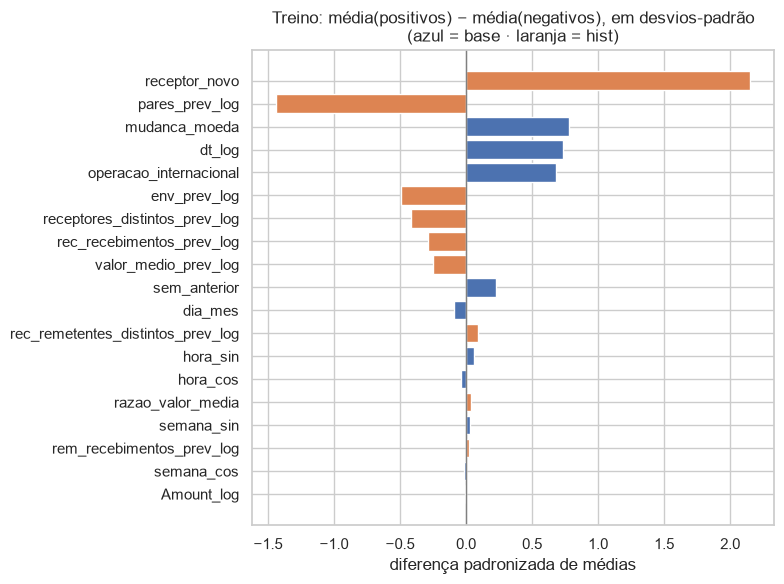

In [8]:
# --- 3) histórico de positivas vs negativas (nº de transações anteriores da conta) — amostra leve
rng_h = np.random.default_rng(SEMENTE)
idx_pos = np.flatnonzero(y_all == 1)
idx_neg = rng_h.choice(np.flatnonzero(y_all == 0), size=min(200_000, int((y_all == 0).sum())), replace=False)
amostra_hist = pd.DataFrame({"anteriores": np.minimum(ctx.pos_grupo[np.r_[idx_pos, idx_neg]], 60),
                             "classe": ["Lavagem"] * len(idx_pos) + ["Normal"] * len(idx_neg)})
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=amostra_hist, x="anteriores", hue="classe", stat="percent", common_norm=False, bins=30, element="step", ax=ax[0])
ax[0].set(title="Transações anteriores da conta (truncado em 60), por classe", xlabel="transações anteriores da conta", ylabel="% dentro da classe")

# --- 5) transações por conta remetente (agregado antes de plotar)
freq_contas = contagem.clip(upper=200).value_counts().sort_index()
ax[1].bar(freq_contas.index, freq_contas.values, color="#4C72B0", width=1.0); ax[1].set_yscale("log")
ax[1].set(title="Transações por conta remetente (truncado em 200)", xlabel="transações da conta", ylabel="nº de contas (log)")
plt.tight_layout(); plt.show()

# --- 4) distribuição temporal dos alvos
mensal = (dataset.groupby(dataset["Timestamp"].dt.to_period("M"))[ALVO].agg(total="count", positivos="sum", taxa="mean")
          .rename_axis("mes").reset_index())
mensal["mes"] = mensal["mes"].astype(str); mensal["taxa_%"] = mensal["taxa"] * 100
fig, ax = plt.subplots(figsize=(10, 4)); ax2 = ax.twinx()
ax.bar(mensal["mes"], mensal["positivos"], color="#C44E52", label="positivos")
ax2.plot(mensal["mes"], mensal["taxa_%"], color="black", marker="o", label="taxa (%)"); ax2.grid(False)
ax.set(title="Positivos por mês e taxa positiva (%)", xlabel="mês", ylabel="nº de positivos"); ax2.set_ylabel("taxa (%)")
ax.tick_params(axis="x", rotation=45)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()
display(mensal.round(4))

# --- 6) separação das classes pelos atributos (TREINO): diferença de médias em unidades de desvio-padrão do treino
y_tr_all = y_all[alvos_treino]
pos_tr = alvos_treino[y_tr_all == 1]
neg_tr = rng_h.choice(alvos_treino[y_tr_all == 0], size=min(1_000_000, int((y_tr_all == 0).sum())), replace=False)
dif = ctx.F_num[pos_tr].mean(0) - ctx.F_num[neg_tr].mean(0)          # F_num já está padronizado com o treino
ordem = np.argsort(np.abs(dif))
fig, ax = plt.subplots(figsize=(8, 6))
cores = ["#4C72B0" if ctx.nomes_num[i] in COLUNAS_BASE else "#DD8452" for i in ordem]
ax.barh([ctx.nomes_num[i] for i in ordem], dif[ordem], color=cores)
ax.axvline(0, color="gray", lw=1)
ax.set(title="Treino: média(positivos) − média(negativos), em desvios-padrão\n(azul = base · laranja = hist)", xlabel="diferença padronizada de médias")
plt.tight_layout(); plt.show()

**O que olhar / o que NÃO permite concluir**

* **Classes:** se a taxa positiva do teste (≈0,119 %) for maior que a do treino (≈0,102 %), AP e precisão do teste **não são diretamente comparáveis** à validação (a linha de base "sem habilidade" muda).
* **Cobertura:** quanto menor a fração de janelas completas, mais o modelo trabalha com preenchimento; `L=20` pode ser quase todo preenchimento para contas pequenas.
  Note também as taxas positivas em janelas **completas × incompletas**: se forem muito diferentes, o *comprimento do histórico* já é um sinal por si só (e a máscara/`env_prev_log` o expõem).
* **Histórico de positivas × negativas:** diferença de forma sugere que o *tamanho do histórico* carrega informação; não diz se o *conteúdo* do histórico ajuda.
* **Barras de diferença padronizada:** mostram quais atributos têm médias diferentes entre classes **no treino**. Média diferente ≠ bom discriminador (a distribuição pode ter cauda) e ≠ causalidade.
  É um indício de por que os atributos `hist` podem importar, não uma prova.

## 8. Dataset e DataLoader (montagem **sob demanda**)

* `SequenciasSAML.__getitem__` recebe uma **lista de posições** (um lote inteiro) e devolve os três tensores do lote — evita montar 512 exemplos um a um em Python.
* O `DataLoader` usa `batch_size=None` (sem *auto-collation*) e um `BatchSampler` que decide **quais** alvos entram:
  `SequentialSampler` (avaliação, ordem preservada) · `RandomSampler` (treino embaralhado) · `WeightedRandomSampler` (treino balanceado — **apenas no treino**).
* `num_workers=0`: as matrizes ficam na memória do processo principal (cópias por *worker* custariam GB).
* Dimensões do lote: `Xn (B, L, k+1)` (k atributos numéricos + máscara) · `Xc (B, L, 5)` (códigos) · `y (B,)`.

In [9]:
class SequenciasSAML(Dataset):
    def __init__(self, ctx, alvos, L, k):
        self.ctx, self.alvos, self.L, self.k = ctx, np.asarray(alvos, dtype=np.int64), L, k

    def __len__(self):
        return len(self.alvos)

    def __getitem__(self, posicoes):                       # posicoes = lista de posições (um lote)
        idx = self.alvos[np.asarray(posicoes)]
        Xn, Xc, y, _, _ = self.ctx.obter_lote(idx, self.L, self.k)
        return torch.from_numpy(Xn), torch.from_numpy(Xc), torch.from_numpy(y)


def criar_loader(ds, batch_size, modo="sequencial", pesos=None, n_amostras=None, semente=SEMENTE):
    g = torch.Generator().manual_seed(semente)
    if modo == "sequencial":
        base = SequentialSampler(ds)
    elif modo == "embaralhado":
        base = RandomSampler(ds, generator=g)
    elif modo == "ponderado":
        base = WeightedRandomSampler(torch.as_tensor(pesos, dtype=torch.double), num_samples=n_amostras,
                                     replacement=True, generator=g)      # limite do torch.multinomial: 2^24 itens
    else:
        raise ValueError(modo)
    return DataLoader(ds, sampler=BatchSampler(base, batch_size=batch_size, drop_last=False), batch_size=None, num_workers=0)


# Inspeção de um lote real
_ds = SequenciasSAML(ctx, alvos_treino[:5000], L=10, k=K_POR_CONJUNTO["hist"])
xn, xc, yb = next(iter(criar_loader(_ds, 32, "sequencial")))
print("Xn:", tuple(xn.shape), xn.dtype, "→ (batch, L, atributos numéricos + máscara)")
print("Xc:", tuple(xc.shape), xc.dtype, "→ (batch, L, categóricas)")
print("y :", tuple(yb.shape), yb.dtype, "→ (batch,)  rótulo da ÚLTIMA transação")

Xn: (32, 10, 20) torch.float32 → (batch, L, atributos numéricos + máscara)
Xc: (32, 10, 5) torch.int64 → (batch, L, categóricas)
y : (32,) torch.float32 → (batch,)  rótulo da ÚLTIMA transação


## 9. Arquitetura (pequena, com *baseline* primeiro)

```
Xc (B,L,5) ─Embedding(4) por coluna─► (B,L,20) ┐
                                               ├─ concat → x (B,L,d_in) ─► LSTM(64) ─► h do ÚLTIMO passo (B,64) ┐
Xn (B,L,k+1) ──────────────────────────────────┘                                                              ├─ concat → (B,64+d_in)
                                                          x do ÚLTIMO passo (B,d_in) ── conexão direta (USAR_SKIP) ┘        │
                                                     Dropout → Linear(·,64) → ReLU → Dropout → Linear(64,1) ─► logit (B,)
```

* **Por que o último passo?** O alvo é a última transação; com preenchimento **à esquerda**, o último passo é sempre real e já "viu" toda a janela.
* **Por que a conexão direta `x_último`?** (🧠) Sem ela, `L=1` seria uma LSTM de um passo só — um *caso especial fraco* —, e a comparação L=1 × L>1 misturaria "ter histórico"
  com "ter um classificador razoável". Com ela, **`L=1` ≈ um MLP nos atributos da transação atual** e a diferença para `L>1` isola a contribuição da recorrência.
* **Loss:** `BCEWithLogitsLoss` (sigmoid + entropia cruzada binária estável). A rede devolve **logit**; probabilidade = `sigmoid(logit)`.
* **Capacidade pequena** (1 camada, 64 unidades, dropout 0,2): baseline defensável antes de qualquer arquitetura maior.

In [10]:
class ClassificadorLSTM(nn.Module):
    def __init__(self, n_num, cardinalidades, emb_dim=EMB_DIM, hidden=HIDDEN, n_camadas=N_CAMADAS, dropout=DROPOUT, skip=USAR_SKIP):
        super().__init__()
        self.skip = skip
        self.embs = nn.ModuleList([nn.Embedding(c, emb_dim, padding_idx=0) for c in cardinalidades])
        d_in = n_num + emb_dim * len(cardinalidades)
        self.lstm = nn.LSTM(d_in, hidden, num_layers=n_camadas, batch_first=True, dropout=dropout if n_camadas > 1 else 0.0)
        d_cab = hidden + (d_in if skip else 0)
        self.cabeca = nn.Sequential(nn.Dropout(dropout), nn.Linear(d_cab, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x_num, x_cat):
        emb = torch.cat([e(x_cat[..., i]) for i, e in enumerate(self.embs)], dim=-1)     # (B,L,5*emb)
        x = torch.cat([x_num, emb], dim=-1)                                                # (B,L,d_in)
        saida, _ = self.lstm(x)                                                            # (B,L,hidden)
        z = saida[:, -1, :]                                                                # (B,hidden)  último passo
        if self.skip:
            z = torch.cat([z, x[:, -1, :]], dim=-1)                                        # (B,hidden+d_in)
        return self.cabeca(z).squeeze(-1)                                                  # (B,) logits


_m = ClassificadorLSTM(K_POR_CONJUNTO["hist"] + 1, ctx.cardinalidades)
print(_m)
print("Parâmetros treináveis:", sum(p.numel() for p in _m.parameters() if p.requires_grad))
with torch.no_grad():
    print("Logits do lote de teste:", tuple(_m(xn, xc).shape), "(esperado: (32,))")
del _m

ClassificadorLSTM(
  (embs): ModuleList(
    (0): Embedding(8, 4, padding_idx=0)
    (1-2): 2 x Embedding(14, 4, padding_idx=0)
    (3-4): 2 x Embedding(19, 4, padding_idx=0)
  )
  (lstm): LSTM(40, 64, batch_first=True)
  (cabeca): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=104, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parâmetros treináveis: 34217
Logits do lote de teste: (32,) (esperado: (32,))


## 10. Métricas, limiar, estratégias de balanceamento e treino

**Regras de higiene que o código impõe**
* o **limiar** é escolhido na **validação** (melhor F1; também reporto "recall ≥ 80 %") e **congelado**;
* a escolha de estratégia/conjunto/tamanho usa **Average Precision (AP) na validação completa** (distribuição natural);
* balanceamento **somente no treino**; validação e teste mantêm a distribuição natural;
* o **teste** só é lido na seção 15, **uma vez**.

> *Nomenclatura:* `average_precision_score` é chamada de **Average Precision (AP)**; não a tratamos como área trapezoidal sob a curva PR.

**Estratégias (comparadas separadamente, só no treino):**

| Estratégia | O que faz | Risco |
|---|---|---|
| `baseline` | amostra natural (500 k), loss normal | poucos positivos (~500) |
| `pos_weight` | mesma amostra; `pos_weight = #neg/#pos` (≈1000) | recall ↑ mas falsos positivos ↑; gradientes muito ruidosos |
| `pos_weight_sqrt` | mesma amostra; `pos_weight = √(#neg/#pos)` (≈32) | meio-termo (🧠 variante nova) |
| `sampler_ponderado` | `WeightedRandomSampler` sobre **todo** o treino (~50 % positivos por época) | repete positivos (sobreajuste); probabilidades deslocadas |
| `undersampling` | todas as positivas + 150 k negativas | descarta informação de negativas |

SMOTE **não** é usado: interpolar sequências cria exemplos sem coerência temporal.
> Probabilidades de modelos treinados com `pos_weight`/*sampler* ficam **deslocadas para cima** (não calibradas): por isso o limiar vem da validação, não de 0,5.

In [11]:
def metricas_binarias(y_real, prob, limiar):
    pred = (prob >= limiar).astype(int)
    return {"accuracy": accuracy_score(y_real, pred), "precision": precision_score(y_real, pred, zero_division=0),
            "recall": recall_score(y_real, pred, zero_division=0), "f1": f1_score(y_real, pred, zero_division=0),
            "AP": average_precision_score(y_real, prob) if y_real.sum() else np.nan, "limiar": float(limiar)}


def limiar_melhor_f1(y_real, prob):
    p, r, thr = precision_recall_curve(y_real, prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return float(thr[i]), float(f1[i])


def limiar_recall_minimo(y_real, prob, recall_min=0.80):
    p, r, thr = precision_recall_curve(y_real, prob)
    ok = np.where(r[:-1] >= recall_min)[0]
    if len(ok) == 0:
        return float(thr[0]), float(p[0])
    i = ok[np.argmax(p[ok])]
    return float(thr[i]), float(p[i])


@torch.no_grad()
def prever_lstm(modelo, ds, calcular_loss=False):
    # Devolve (probabilidades na ordem de ds.alvos, loss média sem pesos ou None).
    modelo.eval()
    crit = nn.BCEWithLogitsLoss(reduction="sum")
    probs, soma = [], 0.0
    for xn_, xc_, yb_ in criar_loader(ds, BATCH_AVAL, "sequencial"):
        logit = modelo(xn_.to(DISPOSITIVO), xc_.to(DISPOSITIVO))
        if calcular_loss:
            soma += crit(logit, yb_.to(DISPOSITIVO)).item()
        probs.append(torch.sigmoid(logit).cpu().numpy())
    return np.concatenate(probs), (soma / len(ds) if calcular_loss else None)


ESTRATEGIAS = ["baseline", "pos_weight", "pos_weight_sqrt", "sampler_ponderado", "undersampling"]


def preparar_estrategia(nome, semente):
    # SOMENTE treino. Mesma semente => mesma amostra em baseline / pos_weight / pos_weight_sqrt.
    rng = np.random.default_rng(semente)
    y_t = y_all[alvos_treino]
    if nome in ("baseline", "pos_weight", "pos_weight_sqrt"):
        sel = np.sort(rng.choice(len(alvos_treino), size=min(N_TREINO_NATURAL, len(alvos_treino)), replace=False))
        alvos = alvos_treino[sel]
        ys = y_all[alvos]
        razao = float((ys == 0).sum() / max((ys == 1).sum(), 1))              # calculada SÓ no treino
        pw = {"baseline": None, "pos_weight": razao, "pos_weight_sqrt": float(np.sqrt(razao))}[nome]
        return dict(alvos=alvos, modo="embaralhado", pos_weight=pw)
    if nome == "sampler_ponderado":
        n_pos = max(int((y_t == 1).sum()), 1)
        n_neg = max(len(y_t) - n_pos, 1)
        pesos = np.where(y_t == 1, 1.0 / n_pos, 1.0 / n_neg)               # ~50 % de positivos esperados por época
        return dict(alvos=alvos_treino, modo="ponderado", pesos=pesos, n_amostras=AMOSTRAS_POR_EPOCA, pos_weight=None)
    if nome == "undersampling":
        pos, neg = alvos_treino[y_t == 1], alvos_treino[y_t == 0]
        neg_sel = rng.choice(neg, size=min(N_NEG_UNDER, len(neg)), replace=False)
        return dict(alvos=np.sort(np.concatenate([pos, neg_sel])), modo="embaralhado", pos_weight=None)
    raise ValueError(nome)


# subconjunto natural da validação para monitorar o treino a cada época (a validação completa é usada ao final)
_rng_val = np.random.default_rng(SEMENTE + 1000)
alvos_val_monitor = np.sort(_rng_val.choice(alvos_val, size=min(MAX_VAL_EPOCA, len(alvos_val)), replace=False))
y_val_monitor, y_val_full = y_all[alvos_val_monitor], y_all[alvos_val]
print(f"Monitor de validação: {len(alvos_val_monitor):,} alvos, {int(y_val_monitor.sum())} positivos | validação completa: {int(y_val_full.sum())} positivos")

resultados = {}      # (estratégia, conjunto, L, semente) -> dict


def executar_experimento(estrategia, L, conjunto, semente=SEMENTE, epocas=None, verbose=True):
    chave = (estrategia, conjunto, L, semente)
    if chave in resultados:
        return resultados[chave]
    epocas = epocas or EPOCAS
    k = K_POR_CONJUNTO[conjunto]
    torch.manual_seed(semente); np.random.seed(semente)
    cfg = preparar_estrategia(estrategia, semente)
    ds_tr = SequenciasSAML(ctx, cfg["alvos"], L, k)
    ds_mon = SequenciasSAML(ctx, alvos_val_monitor, L, k)
    ds_full = SequenciasSAML(ctx, alvos_val, L, k)
    y_tr = y_all[cfg["alvos"]]

    modelo = ClassificadorLSTM(k + 1, ctx.cardinalidades).to(DISPOSITIVO)
    pw = None if cfg["pos_weight"] is None else torch.tensor([cfg["pos_weight"]], dtype=torch.float32, device=DISPOSITIVO)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    otim = torch.optim.Adam(modelo.parameters(), lr=LR)

    if verbose:
        print(f"\n=== {estrategia} | {conjunto} (k={k}) | L={L} | semente={semente} | alvos de treino/época: "
              f"{cfg.get('n_amostras') or len(cfg['alvos']):,} | positivos no pool: {int(y_tr.sum()):,} | pos_weight={cfg['pos_weight']}")
    t_ini = time.perf_counter()
    hist, melhor_ap, melhor_estado, sem_melhora = [], -1.0, None, 0
    for ep in range(1, epocas + 1):
        t0 = time.perf_counter()
        modelo.train()
        loader = criar_loader(ds_tr, BATCH_TREINO, cfg["modo"], cfg.get("pesos"), cfg.get("n_amostras"), semente=semente + ep)
        soma, n = 0.0, 0
        for xn_, xc_, yb_ in loader:
            xn_, xc_, yb_ = xn_.to(DISPOSITIVO), xc_.to(DISPOSITIVO), yb_.to(DISPOSITIVO)
            otim.zero_grad(set_to_none=True)
            loss = crit(modelo(xn_, xc_), yb_)
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            otim.step()
            soma += loss.item() * len(yb_); n += len(yb_)
        prob_mon, loss_val = prever_lstm(modelo, ds_mon, calcular_loss=True)
        ap_mon = average_precision_score(y_val_monitor, prob_mon) if y_val_monitor.sum() else 0.0
        hist.append({"epoca": ep, "loss_treino": soma / n, "loss_val": loss_val, "AP_val_monitor": ap_mon})
        if verbose:
            print(f"  época {ep:>2d}: loss treino={soma / n:.4f} | loss val={loss_val:.4f} | AP val(monitor)={ap_mon:.4f} | {time.perf_counter() - t0:.0f}s")
        if ap_mon > melhor_ap:
            melhor_ap, sem_melhora = ap_mon, 0
            melhor_estado = {kk: v.detach().cpu().clone() for kk, v in modelo.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= PACIENCIA:
                if verbose:
                    print(f"  early stopping (sem melhora há {PACIENCIA} épocas)")
                break

    modelo.load_state_dict(melhor_estado)
    prob_val, _ = prever_lstm(modelo, ds_full)                     # validação COMPLETA, distribuição natural
    thr, f1_val = limiar_melhor_f1(y_val_full, prob_val)
    thr_r, prec_r = limiar_recall_minimo(y_val_full, prob_val, 0.80)
    res = {"estrategia": estrategia, "conjunto": conjunto, "L": L, "semente": semente, "k": k,
           "historico": pd.DataFrame(hist), "estado": melhor_estado, "prob_val": prob_val.astype(np.float32),
           "AP_val": average_precision_score(y_val_full, prob_val), "limiar_f1": thr, "F1_val": f1_val,
           "limiar_recall80": thr_r, "precisao_recall80": prec_r, "segundos": time.perf_counter() - t_ini,
           "bateu_limite_epocas": len(hist) == epocas and sem_melhora < PACIENCIA}
    resultados[chave] = res
    if verbose:
        print(f"  → VALIDAÇÃO COMPLETA: AP={res['AP_val']:.4f} | melhor F1={f1_val:.4f} @ {thr:.4f} | recall≥80% → precisão={prec_r:.4f} "
              f"| {res['segundos']:.0f}s" + (" | ⚠️ atingiu o limite de épocas" if res["bateu_limite_epocas"] else ""))
    return res


def tabela_resultados(chaves):
    return pd.DataFrame([{"estratégia": c[0], "conjunto": c[1], "L": c[2], "semente": c[3], "AP_val": resultados[c]["AP_val"],
                          "F1_val": resultados[c]["F1_val"], "limiar_F1": resultados[c]["limiar_f1"],
                          "precisão@recall≥80%": resultados[c]["precisao_recall80"], "épocas": len(resultados[c]["historico"]),
                          "limite_épocas": resultados[c]["bateu_limite_epocas"], "segundos": resultados[c]["segundos"]} for c in chaves])


def curva_pr_fina(y, prob, max_pontos=1500):
    p, r, _ = precision_recall_curve(y, prob)
    idx = np.unique(np.linspace(0, len(r) - 1, min(max_pontos, len(r))).astype(int))
    return r[idx], p[idx]


def grafico_loss(chaves, titulo="Loss de treino e validação por época"):
    fig, axes = plt.subplots(1, len(chaves), figsize=(4.4 * len(chaves), 3.8), squeeze=False)
    for ax, c in zip(axes[0], chaves):
        h = resultados[c]["historico"]
        ax.plot(h["epoca"], h["loss_treino"], marker="o", label="treino")
        ax.plot(h["epoca"], h["loss_val"], marker="s", label="validação (monitor)")
        ax.set(title=f"{c[0]} | {c[1]} | L={c[2]}", xlabel="época", ylabel="BCEWithLogits"); ax.legend()
    plt.suptitle(titulo, y=1.03); plt.tight_layout(); plt.show()


def grafico_pr_validacao(chaves, titulo="Curvas Precisão × Recall — validação completa"):
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    for c in chaves:
        r, p = curva_pr_fina(y_val_full, resultados[c]["prob_val"])
        ax.plot(r, p, lw=1.8, label=f"{c[0]} | {c[1]} | L={c[2]} (AP={resultados[c]['AP_val']:.3f})")
    ax.axhline(float(y_val_full.mean()), color="gray", ls="--", label="sem habilidade")
    ax.set(title=titulo, xlabel="Recall", ylabel="Precisão", xlim=(0, 1), ylim=(0, 1.02)); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

Monitor de validação: 400,000 alvos, 390 positivos | validação completa: 1412 positivos


## 11. Experimento A — estratégias de balanceamento (`hist`, `L = TAMANHO_REF`, semente única)

"Sequência" **não** balanceia as classes: a proporção positiva continua ≈ 0,1 % (depende só do rótulo da última transação).
Comparamos as cinco estratégias **separadamente** (e só no treino), usando o conjunto `hist` (o de maior informação) e `L=10`.
A escolha usa **AP na validação completa**.


=== baseline | hist (k=19) | L=10 | semente=42 | alvos de treino/época: 500,000 | positivos no pool: 495 | pos_weight=None
  época  1: loss treino=0.0138 | loss val=0.0037 | AP val(monitor)=0.5105 | 33s
  época  2: loss treino=0.0039 | loss val=0.0015 | AP val(monitor)=0.8845 | 32s
  época  3: loss treino=0.0027 | loss val=0.0008 | AP val(monitor)=0.9386 | 32s
  época  4: loss treino=0.0020 | loss val=0.0005 | AP val(monitor)=0.9646 | 33s
  época  5: loss treino=0.0018 | loss val=0.0005 | AP val(monitor)=0.9724 | 26s
  época  6: loss treino=0.0017 | loss val=0.0006 | AP val(monitor)=0.9718 | 15s
  época  7: loss treino=0.0015 | loss val=0.0003 | AP val(monitor)=0.9789 | 20s
  época  8: loss treino=0.0014 | loss val=0.0004 | AP val(monitor)=0.9757 | 16s
  época  9: loss treino=0.0013 | loss val=0.0003 | AP val(monitor)=0.9775 | 17s
  época 10: loss treino=0.0013 | loss val=0.0004 | AP val(monitor)=0.9746 | 16s
  época 11: loss treino=0.0011 | loss val=0.0007 | AP val(monitor)=0.9684 | 

,estratégia,conjunto,L,semente,AP_val,F1_val,limiar_F1,precisão@recall≥80%,épocas,limite_épocas,segundos
4,undersampling,hist,10,42,0.9811,0.9665,0.9974,0.9991,14,False,113.7561
0,baseline,hist,10,42,0.9761,0.9603,0.4858,1.0000,11,False,268.4439
3,sampler_ponderado,hist,10,42,0.9755,0.9602,0.9997,1.0000,20,True,268.7271
1,pos_weight,hist,10,42,0.9717,0.9629,0.9999,0.9965,11,False,172.8939
2,pos_weight_sqrt,hist,10,42,0.9677,0.9452,0.9883,0.9956,11,False,178.2875


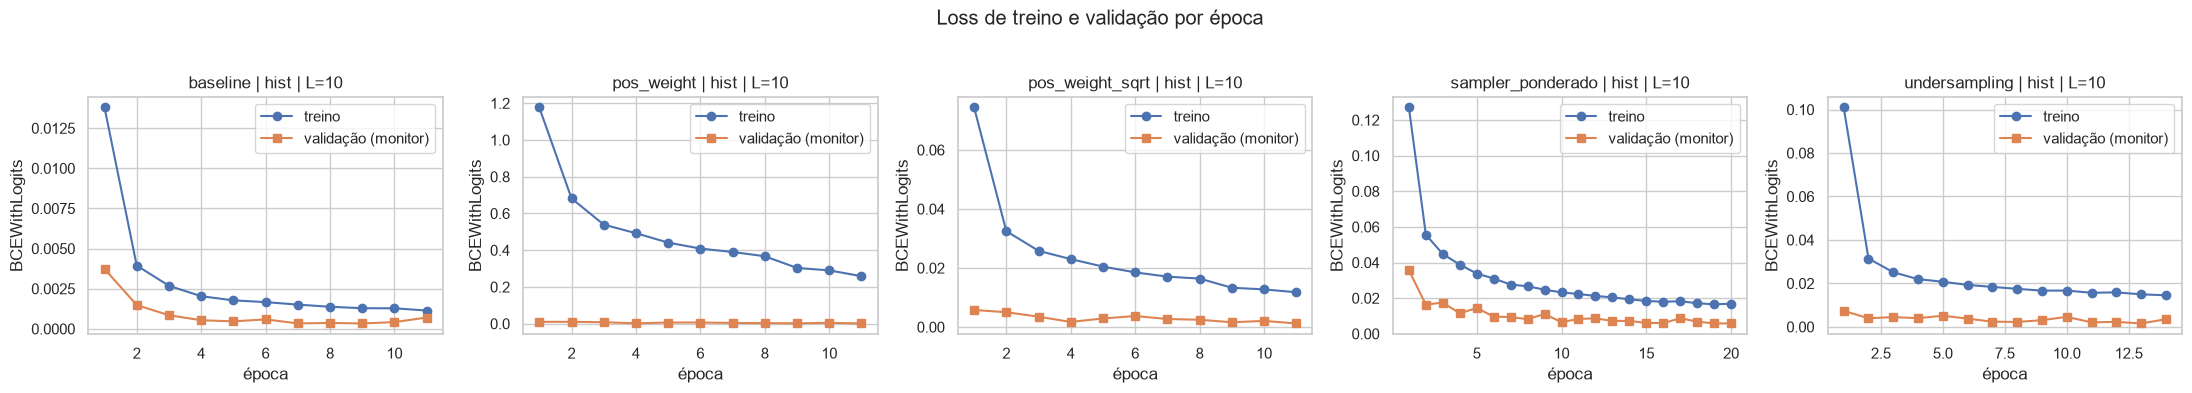

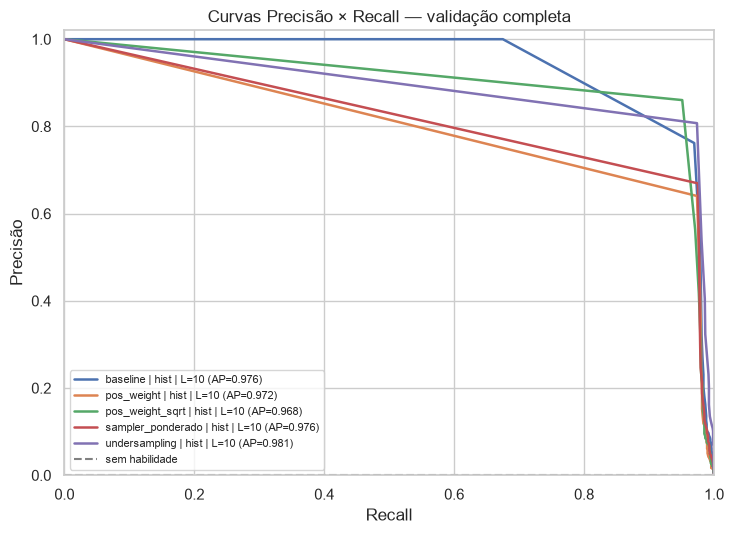

Estratégia escolhida (maior AP na validação): undersampling


In [12]:
CONJUNTO_A = "hist"
for e in ESTRATEGIAS:
    executar_experimento(e, TAMANHO_REF, CONJUNTO_A, SEMENTE)

tab_estrategias = tabela_resultados([(e, CONJUNTO_A, TAMANHO_REF, SEMENTE) for e in ESTRATEGIAS]).sort_values("AP_val", ascending=False)
display(tab_estrategias.round(4))
grafico_loss([(e, CONJUNTO_A, TAMANHO_REF, SEMENTE) for e in ESTRATEGIAS])
grafico_pr_validacao([(e, CONJUNTO_A, TAMANHO_REF, SEMENTE) for e in ESTRATEGIAS])

ESTRATEGIA_ESCOLHIDA = tab_estrategias.iloc[0]["estratégia"]          # 🧠 critério: maior AP na VALIDAÇÃO
print("Estratégia escolhida (maior AP na validação):", ESTRATEGIA_ESCOLHIDA)

**O que olhar / como interpretar**

* `loss_treino` **não é comparável** entre estratégias (pesos/amostras diferentes). Compare **AP na validação** e as curvas PR.
* Se `loss_val` sobe enquanto `loss_treino` cai → sobreajuste (esperado em `sampler_ponderado`, que repete positivos muitas vezes por época).
* A coluna `limite_épocas` mostra se o treino **bateu o teto de épocas** sem *early stopping*. Se for `True` em várias estratégias, o resultado pode estar **subtreinado** (H3) — aumente `EPOCAS` antes de concluir.
* Diferenças pequenas de AP podem estar dentro do ruído (≈1.400 positivos na validação; uma semente). Para decidir entre estratégias *próximas*, repita com mais sementes.

## 12. Experimento B — escada de ablação: conjunto de atributos × tamanho `L`

Com a estratégia escolhida, variamos **o que a rede vê**:

| Linha da escada | Responde |
|---|---|
| `base`, `L=1` | só a transação atual (atributos simples) |
| `base`, `L>1` | a sequência acrescenta algo **sem** agregados do passado? (era a pergunta do notebook anterior) |
| `hist`, `L=1` | transação atual + resumo de todo o passado (≈ um MLP nos mesmos atributos que o GBM) |
| `hist`, `L>1` | a sequência acrescenta algo **além** dos agregados? (**H1′**) |

`L=1` é a ablação "sem histórico recente". Atenção: **mais histórico ≠ melhor**: janelas longas têm mais preenchimento e custam mais.


=== undersampling | base (k=10) | L=1 | semente=42 | alvos de treino/época: 156,764 | positivos no pool: 6,764 | pos_weight=None
  época  1: loss treino=0.1656 | loss val=0.0424 | AP val(monitor)=0.0107 | 4s
  época  2: loss treino=0.1282 | loss val=0.0496 | AP val(monitor)=0.0370 | 4s
  época  3: loss treino=0.1240 | loss val=0.0377 | AP val(monitor)=0.0642 | 4s
  época  4: loss treino=0.1214 | loss val=0.0408 | AP val(monitor)=0.0644 | 3s
  época  5: loss treino=0.1192 | loss val=0.0392 | AP val(monitor)=0.0686 | 3s
  época  6: loss treino=0.1173 | loss val=0.0396 | AP val(monitor)=0.0820 | 3s
  época  7: loss treino=0.1144 | loss val=0.0434 | AP val(monitor)=0.0890 | 3s
  época  8: loss treino=0.1135 | loss val=0.0311 | AP val(monitor)=0.0917 | 3s
  época  9: loss treino=0.1123 | loss val=0.0385 | AP val(monitor)=0.0939 | 3s
  época 10: loss treino=0.1112 | loss val=0.0407 | AP val(monitor)=0.0968 | 3s
  época 11: loss treino=0.1103 | loss val=0.0337 | AP val(monitor)=0.0999 | 3s
 

,estratégia,conjunto,L,semente,AP_val,F1_val,limiar_F1,precisão@recall≥80%,épocas,limite_épocas,segundos
0,undersampling,base,1,42,0.0829,0.1287,0.6639,0.0057,17,False,58.3659
1,undersampling,base,5,42,0.3475,0.3847,0.9754,0.0331,20,True,99.5992
2,undersampling,base,10,42,0.4133,0.4332,0.9806,0.0407,20,True,194.3785
3,undersampling,base,20,42,0.4259,0.4355,0.9858,0.0414,18,False,207.1610
4,undersampling,hist,1,42,0.9804,0.9809,0.9407,1.0000,17,False,58.7577
5,undersampling,hist,5,42,0.9779,0.9640,0.9804,0.9983,12,False,72.9030
6,undersampling,hist,10,42,0.9811,0.9665,0.9974,0.9991,14,False,113.7561
7,undersampling,hist,20,42,0.9816,0.9650,0.9966,0.9984,14,False,172.0047


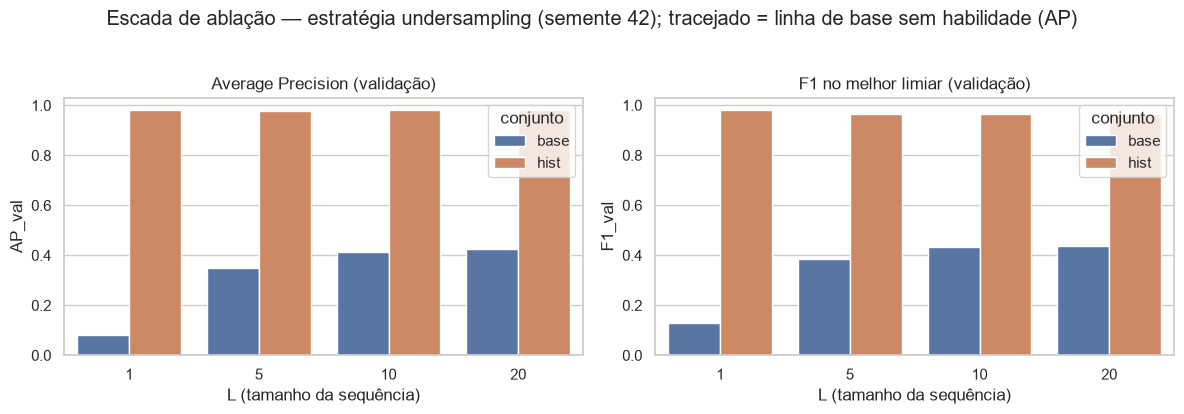

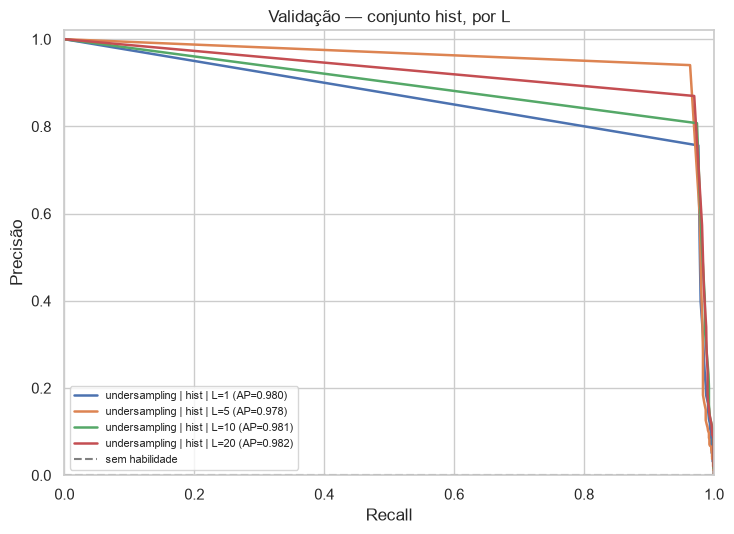

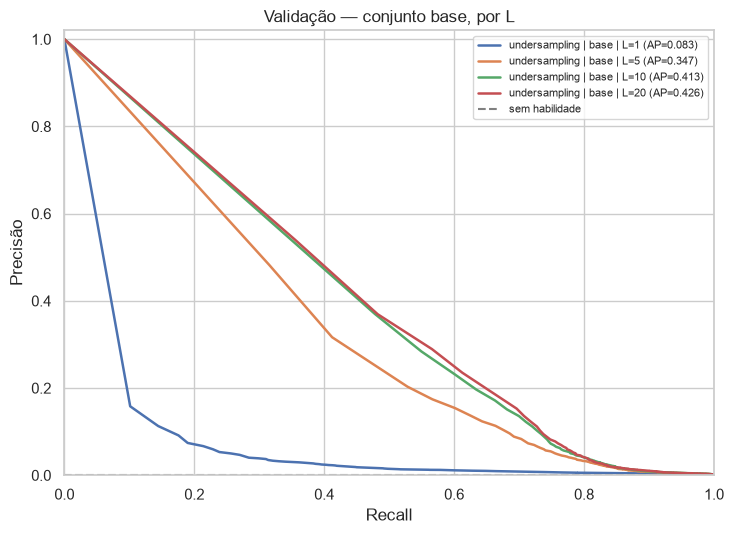

Configuração final (maior AP na validação): conjunto=hist, L=20
Melhor do outro conjunto (base): L=20 (AP_val=0.4259)


In [13]:
for conj in ("base", "hist"):
    for L_ in TAMANHOS:
        executar_experimento(ESTRATEGIA_ESCOLHIDA, L_, conj, SEMENTE)

chaves_B = [(ESTRATEGIA_ESCOLHIDA, conj, L_, SEMENTE) for conj in ("base", "hist") for L_ in TAMANHOS]
tab_escada = tabela_resultados(chaves_B)
display(tab_escada.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, tit in zip(ax, ["AP_val", "F1_val"], ["Average Precision (validação)", "F1 no melhor limiar (validação)"]):
    sns.barplot(data=tab_escada, x="L", y=col, hue="conjunto", ax=a, palette=["#4C72B0", "#DD8452"])
    a.axhline(float(y_val_full.mean()) if col == "AP_val" else 0, color="gray", ls="--", lw=1)
    a.set(title=tit, xlabel="L (tamanho da sequência)", ylabel=col)
plt.suptitle(f"Escada de ablação — estratégia {ESTRATEGIA_ESCOLHIDA} (semente {SEMENTE}); tracejado = linha de base sem habilidade (AP)", y=1.03)
plt.tight_layout(); plt.show()

grafico_pr_validacao([(ESTRATEGIA_ESCOLHIDA, "hist", L_, SEMENTE) for L_ in TAMANHOS], "Validação — conjunto hist, por L")
grafico_pr_validacao([(ESTRATEGIA_ESCOLHIDA, "base", L_, SEMENTE) for L_ in TAMANHOS], "Validação — conjunto base, por L")

# 🧠 configuração "final": maior AP na VALIDAÇÃO (semente única); as demais linhas viram ablações
melhor = tab_escada.sort_values("AP_val", ascending=False).iloc[0]
CONJ_FINAL, L_FINAL = melhor["conjunto"], int(melhor["L"])
outro = "base" if CONJ_FINAL == "hist" else "hist"
melhor_outro = tab_escada[tab_escada["conjunto"] == outro].sort_values("AP_val", ascending=False).iloc[0]
print(f"Configuração final (maior AP na validação): conjunto={CONJ_FINAL}, L={L_FINAL}")
print(f"Melhor do outro conjunto ({outro}): L={int(melhor_outro['L'])} (AP_val={melhor_outro['AP_val']:.4f})")

**Como interpretar a escada (sem exagerar)**

* `hist, L=1` ≫ `base, L=1`: os agregados do passado carregam o sinal (H2). Isso não é mérito da LSTM: o GBM com os mesmos atributos deve captar o mesmo.
* `hist, L>1` ≈ `hist, L=1` (diferença menor que o desvio entre sementes, ver Experimento C): **não há evidência** de que a *sequência* acrescente algo além dos agregados, com estes atributos.
* `base, L>1` ≫ `base, L=1`: a recorrência recupera parte do que os agregados dão de graça (a sequência "reconstrói" histórico).
* Uma única semente por linha: use o Experimento C antes de afirmar qualquer diferença.

## 13. Experimento C — variabilidade entre sementes (finalistas)

Repetimos as configurações **finalistas** com várias sementes (inicialização, amostra de treino e ordem dos lotes mudam). Isso dá a ordem de grandeza do ruído.
Finalistas (🧠 decididos **pela validação**, antes do teste):

1. `LSTM final`: melhor (conjunto, L) da escada;
2. `LSTM final, L=1` (ablação da sequência): mesmo conjunto, sem histórico recente;
3. `LSTM outro conjunto`: melhor L do outro conjunto (ablação dos agregados).

Finalistas: {'LSTM final': ('undersampling', 'hist', 20), 'LSTM hist L=1 (sem histórico recente)': ('undersampling', 'hist', 1), 'LSTM base (melhor L)': ('undersampling', 'base', 20)}

=== undersampling | hist (k=19) | L=20 | semente=43 | alvos de treino/época: 156,764 | positivos no pool: 6,764 | pos_weight=None
  época  1: loss treino=0.0955 | loss val=0.0098 | AP val(monitor)=0.8407 | 13s
  época  2: loss treino=0.0317 | loss val=0.0068 | AP val(monitor)=0.9505 | 12s
  época  3: loss treino=0.0249 | loss val=0.0035 | AP val(monitor)=0.9462 | 12s
  época  4: loss treino=0.0223 | loss val=0.0033 | AP val(monitor)=0.9754 | 13s
  época  5: loss treino=0.0205 | loss val=0.0046 | AP val(monitor)=0.9820 | 14s
  época  6: loss treino=0.0192 | loss val=0.0021 | AP val(monitor)=0.9790 | 13s
  época  7: loss treino=0.0180 | loss val=0.0020 | AP val(monitor)=0.9837 | 12s
  época  8: loss treino=0.0174 | loss val=0.0019 | AP val(monitor)=0.9704 | 11s
  época  9: loss treino=0.0169 | loss val=0.0

,modelo,semente,AP_val,F1_val,épocas,limite_épocas
0,LSTM final,42,0.9816,0.9650,14,False
1,LSTM final,43,0.9851,0.9678,16,False
2,LSTM final,44,0.9823,0.9673,13,False
3,LSTM hist L=1 (sem histórico recente),42,0.9804,0.9809,17,False
4,LSTM hist L=1 (sem histórico recente),43,0.9797,0.9769,14,False
5,LSTM hist L=1 (sem histórico recente),44,0.9809,0.9809,20,True
6,LSTM base (melhor L),42,0.4259,0.4355,18,False
7,LSTM base (melhor L),43,0.4344,0.4561,20,True
8,LSTM base (melhor L),44,0.4286,0.4397,20,True


,AP_val_media,AP_val_dp,F1_val_media,F1_val_dp,n_sementes
modelo,,,,,
LSTM final,0.9830,0.0018,0.9667,0.0015,3
LSTM hist L=1 (sem histórico recente),0.9803,0.0006,0.9796,0.0023,3
LSTM base (melhor L),0.4296,0.0043,0.4438,0.0109,3


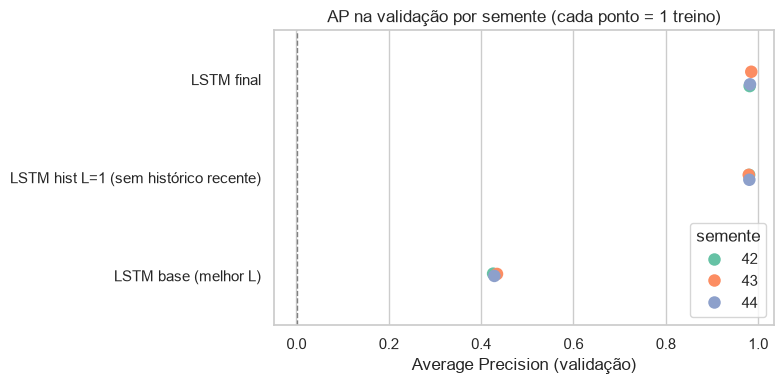

In [14]:
FINALISTAS = {
    "LSTM final": (ESTRATEGIA_ESCOLHIDA, CONJ_FINAL, L_FINAL),
    f"LSTM {CONJ_FINAL} L=1 (sem histórico recente)": (ESTRATEGIA_ESCOLHIDA, CONJ_FINAL, 1),
    f"LSTM {outro} (melhor L)": (ESTRATEGIA_ESCOLHIDA, outro, int(melhor_outro["L"])),
}
# remove duplicatas mantendo o primeiro nome (ex.: se o melhor L já for 1)
vistos, FINALISTAS_UNICOS = {}, {}
for nome, cfg in FINALISTAS.items():
    if cfg not in vistos:
        vistos[cfg] = nome; FINALISTAS_UNICOS[nome] = cfg
FINALISTAS = FINALISTAS_UNICOS
print("Finalistas:", FINALISTAS)

for nome, (e, conj, L_) in FINALISTAS.items():
    for s in SEMENTES:
        executar_experimento(e, L_, conj, s)

linhas_ = []
for nome, (e, conj, L_) in FINALISTAS.items():
    for s in SEMENTES:
        r = resultados[(e, conj, L_, s)]
        linhas_.append({"modelo": nome, "semente": s, "AP_val": r["AP_val"], "F1_val": r["F1_val"], "épocas": len(r["historico"]), "limite_épocas": r["bateu_limite_epocas"]})
por_semente = pd.DataFrame(linhas_)
resumo_sementes = por_semente.groupby("modelo", sort=False).agg(AP_val_media=("AP_val", "mean"), AP_val_dp=("AP_val", "std"),
                                                              F1_val_media=("F1_val", "mean"), F1_val_dp=("F1_val", "std"),
                                                              n_sementes=("semente", "count"))
display(por_semente.round(4)); display(resumo_sementes.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
sns.stripplot(data=por_semente.assign(semente=por_semente["semente"].astype(str)), x="AP_val", y="modelo", hue="semente", size=9, palette="Set2", ax=ax)
ax.axvline(float(y_val_full.mean()), color="gray", ls="--", lw=1)
ax.set(title="AP na validação por semente (cada ponto = 1 treino)", xlabel="Average Precision (validação)", ylabel="")
plt.tight_layout(); plt.show()

**Como usar:** se as médias de `LSTM final` e de `LSTM … L=1` estiverem separadas por **mais que o desvio entre sementes**, há indício de que a sequência acrescenta informação com estes atributos;
caso contrário, não. Com 2–3 sementes o desvio é só uma estimativa grosseira — não é um teste estatístico.

## 14. Baselines tabulares retreinados **aqui**, com as mesmas regras

Para uma comparação justa, treinamos, **na mesma amostra de alvos** do `baseline` da LSTM (`preparar_estrategia("baseline", semente)`),
modelos tabulares que recebem exatamente as **features do último passo** da LSTM:

| Modelo | Entrada | Pergunta |
|---|---|---|
| `GBM base` | 10 numéricas + 5 categóricas da transação atual | piso tabular (≈ `LSTM base, L=1`) |
| `GBM hist` | + 9 agregados do passado | teto tabular com o mesmo resumo do passado que a LSTM `hist` vê (≈ `LSTM hist, L=1`) |
| `Regressão Logística hist` | `hist` + One-Hot das categóricas | referência linear |
| `Dummy (prior)` | — | prediz sempre "normal": AP = prevalência |

* Sem balanceamento (como o `baseline` da LSTM); o **limiar** de cada modelo vem da **validação** (melhor F1), idêntico à regra da LSTM.
* Usa **LightGBM** se estiver instalado; senão, `HistGradientBoostingClassifier` do scikit-learn (🧠 substituto declarado).
* Categóricas no GBM: códigos inteiros tratados como **categóricas nativas**.
* ⚠️ Não é o pipeline exato do `model_completo.ipynb` (❓ o `SAML-D.md` não informa hiperparâmetros, nem como a amostra de 500 mil foi sorteada, nem a semente).
  Por isso os valores **transcritos** do `SAML-D.md` entram só como **referência** na seção 17.

In [15]:
alvos_tab = preparar_estrategia("baseline", SEMENTE)["alvos"]       # MESMA amostra de treino do baseline da LSTM
y_tab = y_all[alvos_tab]
print(f"Amostra tabular: {len(alvos_tab):,} alvos | positivos: {int(y_tab.sum())} | todos dentro do treino: {bool(alvos_tab.max() < i_tr)}")


def X_tab(idx, conjunto):
    k = K_POR_CONJUNTO[conjunto]
    return np.concatenate([ctx.F_num[idx][:, :k], ctx.F_cat[idx].astype(np.float32)], axis=1)       # (n, k+5)


def prever_em_blocos(fn, idx, bloco=500_000):
    return np.concatenate([fn(idx[i:i + bloco]) for i in range(0, len(idx), bloco)]).astype(np.float32)


def criar_gbm(k):
    cat_idx = list(range(k, k + len(COLUNAS_CAT)))
    try:
        import lightgbm as lgb
        m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, random_state=SEMENTE, n_jobs=-1, verbose=-1)
        return m, "LightGBM", {"categorical_feature": cat_idx}
    except ImportError:
        from sklearn.ensemble import HistGradientBoostingClassifier
        m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, categorical_features=cat_idx,
                                           early_stopping=False, random_state=SEMENTE)   # early_stopping="auto" pararia cedo com ~0,1 % de positivos
        return m, "HistGradientBoosting", {}


baselines = {}


def registrar_baseline(nome, prever, t_treino):
    prob_val = prever_em_blocos(prever, alvos_val)
    thr, f1 = limiar_melhor_f1(y_val_full, prob_val)
    baselines[nome] = {"prever": prever, "prob_val": prob_val, "AP_val": average_precision_score(y_val_full, prob_val),
                       "limiar_f1": thr, "F1_val": f1, "segundos": t_treino}
    print(f"{nome:<34s} AP_val={baselines[nome]['AP_val']:.4f} | F1_val={f1:.4f} @ {thr:.4f} | treino {t_treino:.0f}s")


for conj in ("base", "hist"):
    k = K_POR_CONJUNTO[conj]
    modelo_gbm, motor, kw = criar_gbm(k)
    t0 = time.perf_counter()
    modelo_gbm.fit(X_tab(alvos_tab, conj), y_tab, **kw)
    registrar_baseline(f"GBM {conj} ({motor})", (lambda idx, m=modelo_gbm, c=conj: m.predict_proba(X_tab(idx, c))[:, 1]), time.perf_counter() - t0)

# Regressão Logística (hist + One-Hot), sem balanceamento
_k = K_POR_CONJUNTO["hist"]
_ohe = OneHotEncoder(handle_unknown="ignore").fit(ctx.F_cat[alvos_tab])


def X_lr(idx):
    return sparse.hstack([sparse.csr_matrix(ctx.F_num[idx][:, :_k]), _ohe.transform(ctx.F_cat[idx])], format="csr")


t0 = time.perf_counter()
_lr = LogisticRegression(max_iter=300).fit(X_lr(alvos_tab), y_tab)
registrar_baseline("Regressão Logística hist", (lambda idx, m=_lr: m.predict_proba(X_lr(idx))[:, 1]), time.perf_counter() - t0)

# Dummy (prior): AP = prevalência; nunca sinaliza
PREVALENCIA_TREINO = float(y_all[alvos_treino].mean())
baselines["Dummy (prior)"] = {"prever": (lambda idx: np.full(len(idx), PREVALENCIA_TREINO, dtype=np.float32)),
                              "prob_val": np.full(len(alvos_val), PREVALENCIA_TREINO, dtype=np.float32),
                              "AP_val": float(y_val_full.mean()), "limiar_f1": 1.0, "F1_val": 0.0, "segundos": 0.0}
print(f"{'Dummy (prior)':<34s} AP_val={float(y_val_full.mean()):.4f} (= prevalência da validação)")

Amostra tabular: 500,000 alvos | positivos: 495 | todos dentro do treino: True
GBM base (LightGBM)                AP_val=0.0122 | F1_val=0.0650 @ 0.2313 | treino 5s
GBM hist (LightGBM)                AP_val=0.1627 | F1_val=0.3636 @ 1.0000 | treino 5s
Regressão Logística hist           AP_val=0.5570 | F1_val=0.5526 @ 0.1805 | treino 3s
Dummy (prior)                      AP_val=0.0010 (= prevalência da validação)


### 14.1 Validação: LSTM × baselines (ainda **sem** olhar o teste)

,modelo,tipo,AP_val,AP_val_dp,F1_val
0,LSTM final,LSTM,0.9830,0.0018,0.9667
1,LSTM hist L=1 (sem histórico recente),LSTM,0.9803,0.0006,0.9796
2,Regressão Logística hist,tabular,0.5570,NaN,0.5526
3,LSTM base (melhor L),LSTM,0.4296,0.0043,0.4438
4,GBM hist (LightGBM),tabular,0.1627,NaN,0.3636
5,GBM base (LightGBM),tabular,0.0122,NaN,0.0650
6,Dummy (prior),tabular,0.0010,NaN,0.0000


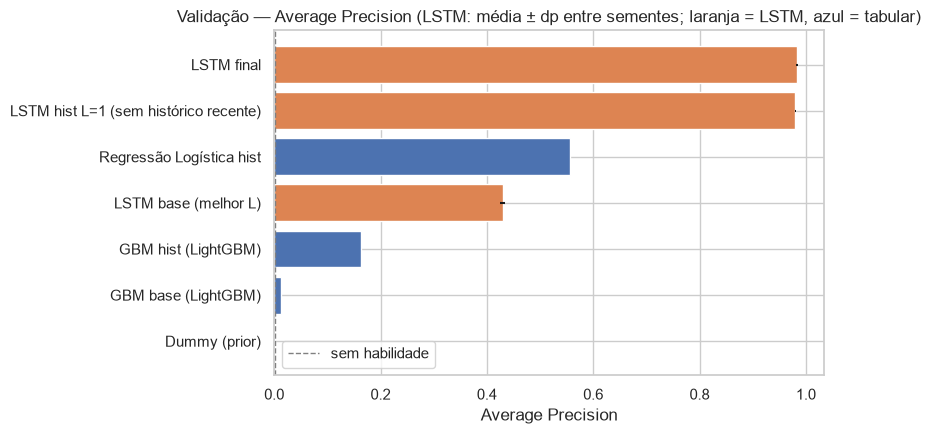

In [16]:
linhas_ = []
for nome, (e, conj, L_) in FINALISTAS.items():
    aps = [resultados[(e, conj, L_, s)]["AP_val"] for s in SEMENTES]
    f1s = [resultados[(e, conj, L_, s)]["F1_val"] for s in SEMENTES]
    linhas_.append({"modelo": nome, "tipo": "LSTM", "AP_val": np.mean(aps), "AP_val_dp": np.std(aps, ddof=1) if len(aps) > 1 else np.nan, "F1_val": np.mean(f1s)})
for nome, b in baselines.items():
    linhas_.append({"modelo": nome, "tipo": "tabular", "AP_val": b["AP_val"], "AP_val_dp": np.nan, "F1_val": b["F1_val"]})
tab_val = pd.DataFrame(linhas_).sort_values("AP_val", ascending=False).reset_index(drop=True)
display(tab_val.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
cor = tab_val["tipo"].map({"LSTM": "#DD8452", "tabular": "#4C72B0"})
ax.barh(tab_val["modelo"], tab_val["AP_val"], xerr=tab_val["AP_val_dp"].fillna(0), color=cor)
ax.axvline(float(y_val_full.mean()), color="gray", ls="--", lw=1, label="sem habilidade")
ax.invert_yaxis(); ax.legend()
ax.set(title="Validação — Average Precision (LSTM: média ± dp entre sementes; laranja = LSTM, azul = tabular)", xlabel="Average Precision")
plt.tight_layout(); plt.show()

**Leitura (sem concluir nada antes de ver os números):**
* `GBM hist` ≫ `GBM base`: os agregados importam também para a árvore → a vantagem do LightGBM do `SAML-D.md` provavelmente vem em boa parte desses atributos, não só do algoritmo.
* `LSTM final` vs `GBM hist`: mesma informação de entrada no último passo. Se a LSTM ficar abaixo, a recorrência (e/ou o treino) **não** compensa a vantagem das árvores neste problema.
  Se ficar próxima ou acima, confirme com sementes e no teste antes de afirmar.
* Esta tabela é **validação**: serve para **escolher** e **congelar**. Ela já foi usada para escolher estratégia/conjunto/L e limiares, então é otimista como estimativa de desempenho futuro.

## 15. Avaliação final — **uma única vez** no teste

Tudo está congelado: estratégia, conjunto, `L`, finalistas, sementes, baselines e **limiar de cada modelo = melhor F1 na validação**.
A função abaixo **lê o teste uma única vez** e levanta erro se for chamada de novo (evita "olhar o teste" repetidamente e escolher o que parece melhor).
Reporta, para cada modelo: acurácia, precisão, recall, F1, AP, matriz de confusão e limiar. Para a LSTM, uma linha **por semente** (média ± dp na tabela).

In [17]:
_TESTE = {"feito": False}


def avaliar_teste_unico():
    if _TESTE["feito"]:
        raise RuntimeError("O teste já foi avaliado. Repetir contamina a estimativa final.")
    _TESTE["feito"] = True
    y_te = y_all[alvos_teste]
    linhas, probs = [], {}
    for nome, (e, conj, L_) in FINALISTAS.items():
        k = K_POR_CONJUNTO[conj]
        ds_te = SequenciasSAML(ctx, alvos_teste, L_, k)
        for s in SEMENTES:
            res = resultados[(e, conj, L_, s)]
            modelo = ClassificadorLSTM(k + 1, ctx.cardinalidades).to(DISPOSITIVO)
            modelo.load_state_dict(res["estado"])
            prob, _ = prever_lstm(modelo, ds_te)
            m = metricas_binarias(y_te, prob, res["limiar_f1"])             # limiar da VALIDAÇÃO
            m.update(modelo=nome, tipo="LSTM", semente=s, cm=confusion_matrix(y_te, (prob >= res["limiar_f1"]).astype(int), labels=[0, 1]))
            linhas.append(m); probs[(nome, s)] = prob
    for nome, b in baselines.items():
        prob = prever_em_blocos(b["prever"], alvos_teste)
        m = metricas_binarias(y_te, prob, b["limiar_f1"])
        m.update(modelo=nome, tipo="tabular", semente=np.nan, cm=confusion_matrix(y_te, (prob >= b["limiar_f1"]).astype(int), labels=[0, 1]))
        linhas.append(m); probs[(nome, np.nan)] = prob
    return pd.DataFrame(linhas), probs, y_te


teste_linhas, probs_teste, y_teste = avaliar_teste_unico()
print(f"Teste: {len(y_teste):,} alvos | {int(y_teste.sum())} positivos ({y_teste.mean():.4%}) — avaliado UMA vez")

METRICAS = ["accuracy", "precision", "recall", "f1", "AP"]
tabela_teste = (teste_linhas.groupby("modelo", sort=False)[METRICAS].agg(["mean", "std"]).round(4))
tabela_teste.columns = [f"{m}_{a}" for m, a in tabela_teste.columns]
display(tabela_teste.sort_values("AP_mean", ascending=False))
print("Matrizes de confusão [[TN FP],[FN TP]] — semente", SEMENTES[0], "(LSTM) e único treino (tabulares):")
for _, r in teste_linhas[(teste_linhas["semente"] == SEMENTES[0]) | teste_linhas["semente"].isna()].iterrows():
    print(f"  {r['modelo']:<48s} limiar={r['limiar']:.4f}  TN={r['cm'][0, 0]:>8,}  FP={r['cm'][0, 1]:>7,}  FN={r['cm'][1, 0]:>5,}  TP={r['cm'][1, 1]:>5,}")

Teste: 1,425,728 alvos | 1697 positivos (0.1190%) — avaliado UMA vez


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,AP_mean,AP_std
modelo,,,,,,,,,,
LSTM final,0.9999,0.0000,0.9761,0.0043,0.9772,0.0047,0.9766,0.0008,0.9934,0.0006
LSTM hist L=1 (sem histórico recente),1.0000,0.0000,0.9937,0.0040,0.9841,0.0026,0.9888,0.0028,0.9931,0.0004
Regressão Logística hist,0.9992,NaN,0.7817,NaN,0.5127,NaN,0.6192,NaN,0.6201,NaN
LSTM base (melhor L),0.9988,0.0001,0.5086,0.0304,0.4113,0.0259,0.4543,0.0217,0.4432,0.0258
GBM hist (LightGBM),0.9963,NaN,0.1817,NaN,0.6052,NaN,0.2795,NaN,0.1120,NaN
GBM base (LightGBM),0.9972,NaN,0.0663,NaN,0.1019,NaN,0.0804,NaN,0.0164,NaN
Dummy (prior),0.9988,NaN,0.0000,NaN,0.0000,NaN,0.0000,NaN,0.0012,NaN


Matrizes de confusão [[TN FP],[FN TP]] — semente 42 (LSTM) e único treino (tabulares):
  LSTM final                                       limiar=0.9966  TN=1,423,987  FP=     44  FN=   38  TP=1,659
  LSTM hist L=1 (sem histórico recente)            limiar=0.9407  TN=1,424,028  FP=      3  FN=   25  TP=1,672
  LSTM base (melhor L)                             limiar=0.9858  TN=1,423,408  FP=    623  FN=1,049  TP=  648
  GBM base (LightGBM)                              limiar=0.2313  TN=1,421,595  FP=  2,436  FN=1,524  TP=  173
  GBM hist (LightGBM)                              limiar=1.0000  TN=1,419,405  FP=  4,626  FN=  670  TP=1,027
  Regressão Logística hist                         limiar=0.1805  TN=1,423,788  FP=    243  FN=  827  TP=  870
  Dummy (prior)                                    limiar=1.0000  TN=1,424,031  FP=      0  FN=1,697  TP=    0


### 15.1 Gráficos do teste

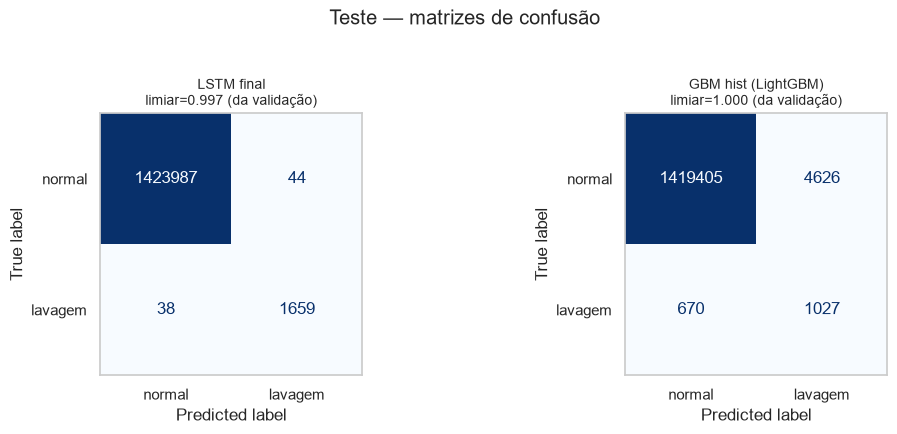

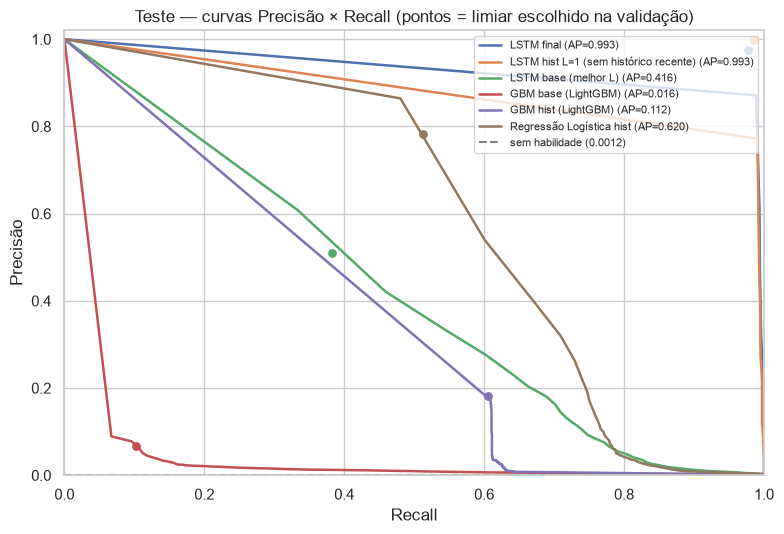

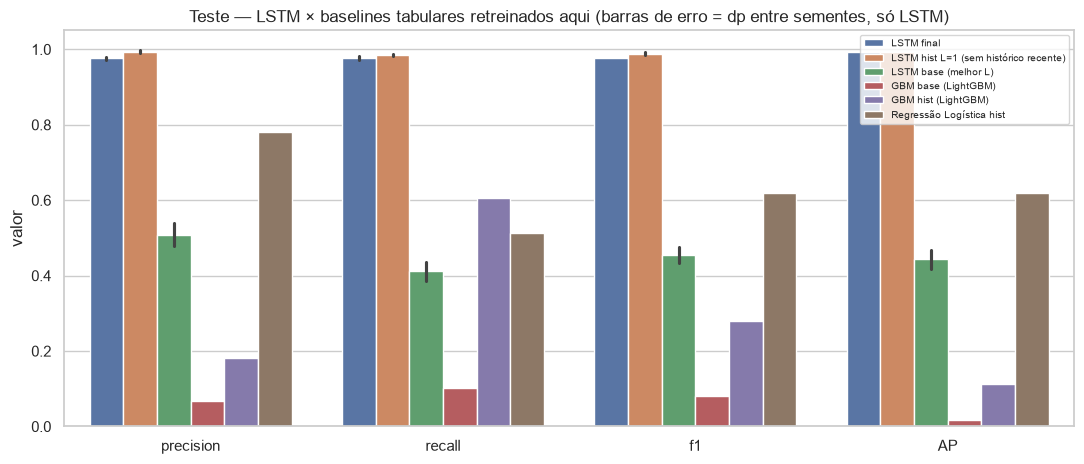

In [18]:
NOME_LSTM = "LSTM final"
NOME_GBM = [n for n in baselines if n.startswith("GBM hist")][0]
s0 = SEMENTES[0]

# (a) matrizes de confusão: LSTM final × GBM hist
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (nome, sem) in zip(ax, [(NOME_LSTM, s0), (NOME_GBM, np.nan)]):
    linha = teste_linhas[(teste_linhas["modelo"] == nome) & ((teste_linhas["semente"] == sem) | (teste_linhas["semente"].isna() & np.isnan(sem)))].iloc[0]
    ConfusionMatrixDisplay(linha["cm"], display_labels=["normal", "lavagem"]).plot(ax=a, cmap="Blues", colorbar=False, values_format="d")
    a.set_title(f"{nome}\nlimiar={linha['limiar']:.3f} (da validação)", fontsize=10); a.grid(False)
plt.suptitle("Teste — matrizes de confusão", y=1.03); plt.tight_layout(); plt.show()

# (b) curvas Precision-Recall
fig, ax = plt.subplots(figsize=(8, 5.5))
for (nome, sem), prob in probs_teste.items():
    if nome == "Dummy (prior)" or (not np.isnan(sem) and sem != s0):
        continue
    r, p = curva_pr_fina(y_teste, prob)
    linha = teste_linhas[(teste_linhas["modelo"] == nome) & ((teste_linhas["semente"] == sem) | (teste_linhas["semente"].isna() & np.isnan(sem)))].iloc[0]
    ax.plot(r, p, lw=1.8, label=f"{nome} (AP={linha['AP']:.3f})")
    ax.scatter([linha["recall"]], [linha["precision"]], s=28, zorder=5)
ax.axhline(y_teste.mean(), color="gray", ls="--", label=f"sem habilidade ({y_teste.mean():.4f})")
ax.set(title="Teste — curvas Precisão × Recall (pontos = limiar escolhido na validação)", xlabel="Recall", ylabel="Precisão", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

# (c) barras de precisão, recall, F1, AP (LSTM: média ± dp entre sementes)
longo = teste_linhas[teste_linhas["modelo"] != "Dummy (prior)"].melt(id_vars=["modelo"], value_vars=["precision", "recall", "f1", "AP"], var_name="métrica", value_name="valor")
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.barplot(data=longo, x="métrica", y="valor", hue="modelo", errorbar="sd", ax=ax)
ax.set(title="Teste — LSTM × baselines tabulares retreinados aqui (barras de erro = dp entre sementes, só LSTM)", xlabel="", ylabel="valor", ylim=(0, 1.05))
ax.legend(fontsize=7, loc="upper right"); plt.tight_layout(); plt.show()

,modelo,bloco,início,fim,positivos,TP,FP,FN,precisão,recall,AP
0,LSTM final,1,2023-07-05,2023-07-17,456,448,12,8,0.9739,0.9825,0.9942
1,LSTM final,2,2023-07-17,2023-07-29,356,339,12,17,0.9658,0.9522,0.9815
2,LSTM final,3,2023-07-29,2023-08-11,347,339,8,8,0.9769,0.9769,0.9946
3,LSTM final,4,2023-08-11,2023-08-23,538,533,12,5,0.9780,0.9907,0.9972
4,GBM hist (LightGBM),1,2023-07-05,2023-07-17,456,245,1041,211,0.1905,0.5373,0.1054
5,GBM hist (LightGBM),2,2023-07-17,2023-07-29,356,240,1056,116,0.1852,0.6742,0.1266
6,GBM hist (LightGBM),3,2023-07-29,2023-08-11,347,226,1190,121,0.1596,0.6513,0.1057
7,GBM hist (LightGBM),4,2023-08-11,2023-08-23,538,316,1339,222,0.1909,0.5874,0.1138


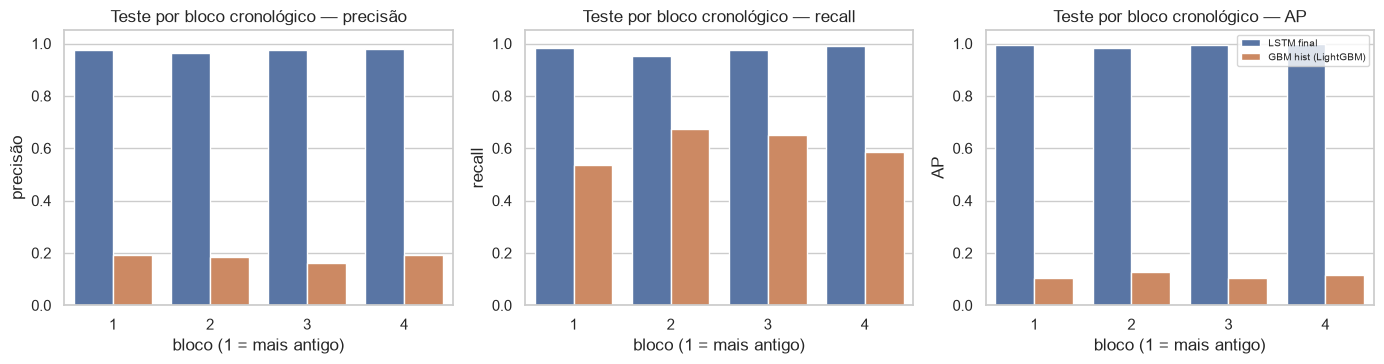

In [19]:
def metricas_por_bloco(alvos, y_real, prob, limiar, n_blocos=4):
    # Blocos cronológicos de IGUAL tamanho (estabilidade temporal): mostra se o desempenho muda ao longo do período do teste.
    cortes = np.linspace(0, len(alvos), n_blocos + 1).astype(int)
    linhas_ = []
    for b in range(n_blocos):
        s_ = slice(cortes[b], cortes[b + 1])
        pred = (prob[s_] >= limiar).astype(int)
        yy = y_real[s_]
        tp = int(((pred == 1) & (yy == 1)).sum()); fp = int(((pred == 1) & (yy == 0)).sum()); fn = int(((pred == 0) & (yy == 1)).sum())
        linhas_.append({"bloco": b + 1, "início": dataset["Timestamp"].iloc[alvos[s_][0]].date(), "fim": dataset["Timestamp"].iloc[alvos[s_][-1]].date(),
                        "positivos": int(yy.sum()), "TP": tp, "FP": fp, "FN": fn,
                        "precisão": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan,
                        "AP": average_precision_score(yy, prob[s_]) if yy.sum() else np.nan})
    return pd.DataFrame(linhas_)


def limiar_de(nome, sem):
    if nome == NOME_LSTM or nome in FINALISTAS:
        e, conj, L_ = FINALISTAS[nome]
        return resultados[(e, conj, L_, sem)]["limiar_f1"]
    return baselines[nome]["limiar_f1"]


blocos = []
for nome, sem in [(NOME_LSTM, s0), (NOME_GBM, np.nan)]:
    t_ = metricas_por_bloco(alvos_teste, y_teste, probs_teste[(nome, sem)], limiar_de(nome, sem))
    t_.insert(0, "modelo", nome); blocos.append(t_)
por_bloco = pd.concat(blocos, ignore_index=True)
display(por_bloco.round(4))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for a, col in zip(ax, ["precisão", "recall", "AP"]):
    sns.barplot(data=por_bloco, x="bloco", y=col, hue="modelo", ax=a)
    a.set(title=f"Teste por bloco cronológico — {col}", xlabel="bloco (1 = mais antigo)", ylim=(0, 1.05))
    if a is not ax[-1]:
        a.get_legend().remove()
ax[-1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**O que olhar / o que NÃO permite concluir**

* **Matrizes de confusão:** mostram o *trade-off* operacional (falsos alertas × casos perdidos) **no limiar da validação**. Outro limiar, outro compromisso; nenhum modelo é "melhor" sem fixar o custo de cada erro.
* **Curvas PR:** comparam os modelos em **todos** os limiares; o ponto marcado é onde cada um foi efetivamente operado. A linha tracejada é a taxa de positivos do teste (desempenho de um sorteio).
* **Barras com dp:** o desvio é só entre sementes de **inicialização/amostra de treino** — não inclui a incerteza por haver apenas ≈1.700 positivos no teste.
* **Blocos cronológicos:** cada bloco tem ≈400 positivos; se as métricas oscilam entre blocos, a estabilidade temporal é limitada (deriva, mudança de comportamento ou apenas ruído amostral — não dá para separar só com este gráfico).
* **Nada aqui prova** que o resultado se repete em dados bancários reais (SAML-D é sintético).

## 16. Respondendo às hipóteses (preencha **depois** de rodar; não preencha antes)

Use apenas números das tabelas acima e cite se vêm da **validação** ou do **teste**.

| Pergunta | Evidência a consultar | Resposta (preencher) |
|---|---|---|
| **H2** — dar à LSTM os agregados do passado reduz a distância para o GBM? | `LSTM base` × `LSTM hist` (seção 12/13); `GBM base` × `GBM hist` (14.1/15) | ? |
| **H3** — o treino anterior estava subtreinado? | coluna `limite_épocas` (11–13) e curvas de loss; comparar com o AP de 0,275 do notebook anterior | ? |
| **H1′** — a sequência (L>1) acrescenta algo além dos agregados? | `LSTM final` × `LSTM … L=1` com mesmas sementes (13) e no teste (15) | ? |
| A LSTM supera o GBM com **os mesmos** atributos? | `LSTM final` × `GBM hist` no teste (15) | ? |
| O desempenho é estável no tempo? | blocos cronológicos (15.1) | ? |

**Regras de leitura:** (i) diferenças menores que o desvio entre sementes **não** são evidência; (ii) escolher o melhor pela validação e confirmar no teste é correto;
escolher pelo teste não é; (iii) um resultado negativo (LSTM ≤ GBM) é um achado legítimo e defensável.

## 17. Comparação com os valores registrados no `SAML-D.md` (**transcritos, não recalculados**)

Resultado final no teste, limiar escolhido na validação, pipeline do `model_completo.ipynb`. **Referência**, não comparação rigorosa:

* ✅ mesmos registros-alvo e partições temporais (contagens conferidas na seção 5);
* ✅ limiar na validação e teste usado uma vez (✅ para o que está registrado no `SAML-D.md`);
* ⚠️ pipeline, hiperparâmetros, **forma de sorteio da amostra de 500 mil** e semente das árvores **não constam** no `SAML-D.md`;
* ⚠️ as árvores receberam atributos próprios (🧠 provavelmente incluindo agregados do passado — ❓ não verificado); os baselines da seção 14 existem exatamente para reduzir essa incerteza;
* ⚠️ a **validação cruzada** do `SAML-D.md` (média ± dp entre *folds* em amostra de 200 mil) é outro protocolo e **não** é comparável às métricas de teste.

In [20]:
ref = pd.DataFrame({
    "modelo": ["LightGBM", "RandomForest", "LogisticRegression", "DummyClassifier"],
    "accuracy": [0.9997, 0.9993, 0.9988, 0.9988],
    "precision": [0.901, 0.710, 0.480, 0.0],
    "recall": [0.8362, 0.7560, 0.1131, 0.0],
    "F1_registrado": [0.8674, 0.7323, 0.01831, 0.0],
    "AP": [0.9200, 0.7396, 0.1823, 0.0012],
}).set_index("modelo")
ref["F1_recalculado"] = 2 * ref["precision"] * ref["recall"] / (ref["precision"] + ref["recall"]).replace(0, np.nan)
ref["fonte"] = "SAML-D.md (transcrito)"
display(ref.round(4))
print("⚠️ Regressão Logística: precisão 0,480 e recall 0,1131 implicam F1 ≈ 0,1831, mas o SAML-D.md registra 0,01831 (não corrigido silenciosamente).")

este = teste_linhas.groupby("modelo", sort=False)[["precision", "recall", "f1", "AP"]].mean()
este["fonte"] = "este notebook (média das sementes)"
display(este.sort_values("AP", ascending=False).round(4))

,accuracy,precision,recall,F1_registrado,AP,F1_recalculado,fonte
modelo,,,,,,,
LightGBM,0.9997,0.901,0.8362,0.8674,0.9200,0.8674,SAML-D.md (transcrito)
RandomForest,0.9993,0.710,0.7560,0.7323,0.7396,0.7323,SAML-D.md (transcrito)
LogisticRegression,0.9988,0.480,0.1131,0.0183,0.1823,0.1831,SAML-D.md (transcrito)
DummyClassifier,0.9988,0.000,0.0000,0.0000,0.0012,NaN,SAML-D.md (transcrito)


⚠️ Regressão Logística: precisão 0,480 e recall 0,1131 implicam F1 ≈ 0,1831, mas o SAML-D.md registra 0,01831 (não corrigido silenciosamente).


,precision,recall,f1,AP,fonte
modelo,,,,,
LSTM final,0.9761,0.9772,0.9766,0.9934,este notebook (média das sementes)
LSTM hist L=1 (sem histórico recente),0.9937,0.9841,0.9888,0.9931,este notebook (média das sementes)
Regressão Logística hist,0.7817,0.5127,0.6192,0.6201,este notebook (média das sementes)
LSTM base (melhor L),0.5086,0.4113,0.4543,0.4432,este notebook (média das sementes)
GBM hist (LightGBM),0.1817,0.6052,0.2795,0.1120,este notebook (média das sementes)
GBM base (LightGBM),0.0663,0.1019,0.0804,0.0164,este notebook (média das sementes)
Dummy (prior),0.0000,0.0000,0.0000,0.0012,este notebook (média das sementes)


## 18. Salvar artefatos (reprodutibilidade)

In [21]:
artefato = {
    "config": {"perfil": PERFIL, "estrategia": ESTRATEGIA_ESCOLHIDA, "finalistas": FINALISTAS, "sementes": SEMENTES, "hidden": HIDDEN,
               "n_camadas": N_CAMADAS, "dropout": DROPOUT, "emb_dim": EMB_DIM, "skip": USAR_SKIP, "lr": LR, "epocas_max": EPOCAS},
    "estados": {(nome, s): resultados[(e, conj, L_, s)]["estado"] for nome, (e, conj, L_) in FINALISTAS.items() for s in SEMENTES},
    "limiares_validacao": {(nome, s): resultados[(e, conj, L_, s)]["limiar_f1"] for nome, (e, conj, L_) in FINALISTAS.items() for s in SEMENTES},
    "colunas_num": ctx.nomes_num, "colunas_cat": COLUNAS_CAT, "escalonador": ctx.escalonador,
    "vocabulario": {c: list(v) for c, v in ctx.vocab.items()}, "cardinalidades": ctx.cardinalidades,
}
joblib.dump(artefato, "lstm_saml_d_v2_artefato.joblib")
print("Salvo: lstm_saml_d_v2_artefato.joblib  (não versionar no Git: adicione ao .gitignore)")

Salvo: lstm_saml_d_v2_artefato.joblib  (não versionar no Git: adicione ao .gitignore)


## 19. Limitações (declare na banca)

* **SAML-D é sintético:** bom desempenho **não** prova desempenho equivalente em bancos reais; o modelo pode aprender padrões artificiais do gerador
  (a distribuição "12 transações por conta" observada no `describe()` da seção 3 é um indício de regularidade sintética).
* **A definição da sequência define o problema:** outra entidade (destinatário, par), outro `L` ou outro rótulo mudam a pergunta aprendida.
* **Atributos `hist` ≠ causalidade** nem prova de lavagem. O modelo é uma **ferramenta de sinalização para análise humana**, não decisão automática de culpa.
* **Empates de timestamp** (≈18 % dos registros têm timestamp repetido): a ordem dentro do mesmo segundo vem do arquivo; "passado" aqui = índice menor, o que pode incluir uma transação do mesmo segundo cuja ordem real é desconhecida.
* **Histórico atravessa partições (só para trás):** alvos de validação/teste usam transações antigas das mesmas contas; é coerente com produção, mas exige que o histórico realmente estivesse disponível no instante.
* **Deriva temporal:** a taxa positiva do teste (0,119 %) é maior que a do treino (0,102 %); o desempenho pode variar por período/entidade/tipo de pagamento.
* **Ruído de avaliação:** ≈1.400–1.700 positivos por partição; poucas sementes; sem intervalo de confiança do teste (um *bootstrap* seria um próximo passo).
* **Validação usada para escolher tudo** (estratégia, conjunto, L, limiar): a estimativa na validação é otimista; só o teste é limpo.
* **Probabilidades não calibradas** quando há `pos_weight`/*sampler*: não interprete a saída como probabilidade real de lavagem.
* **Precision × recall dependem do custo operacional** de investigar um falso alerta versus deixar passar um caso.
* **Comparação com árvores:** só é rigorosa para os baselines treinados aqui; os valores do `SAML-D.md` são referência.

## 20. Pontos a verificar nos materiais (não corrigidos silenciosamente)

1. **F1 da Regressão Logística no teste:** registrado 0,01831; precisão e recall registrados implicam ≈ 0,1831.
2. **`SAML-D.md` — matriz de confusão do Dummy (validação):** mostra `142` falsos negativos, mas o suporte da classe positiva é `1412`.
3. **`SAML-D.md` — acurácia da LR na CV:** aparece como `00.904815` (provável erro de digitação).
4. **`SAML-D.md` — tempos de CV:** as tabelas dos experimentos 1 e 2 repetem exatamente os mesmos tempos (66,6 s / 39,8 s / 8,4 s / 7,7 s); provável cópia.
5. **`SAML-D.md` — precisão do LightGBM na CV:** o texto escreve "0,8629 %" onde o valor é 0,8629 (86,29 %).
6. **Amostra de 500 mil e de 200 mil:** o `SAML-D.md` registra apenas o tamanho e o nº de positivos (486 / 202); não diz se o sorteio foi aleatório ou das primeiras linhas, nem a semente → a equivalência com a amostra da LSTM é **não verificável**.
7. **Validação cruzada:** o `SAML-D.md` cita *KFold*; não fica claro se foi temporal. O desvio-padrão alto do PR-AUC (0,28) é compatível com ruído e/ou variação temporal, mas isso é hipótese.
8. **Seleção de modelo com o teste:** o notebook anterior relata que a versão inicial do `model_completo.ipynb` escolhia o "melhor modelo" pelo PR-AUC **do teste** (corrigido para validação). ❓ Não verifiquei; se você usou a versão antiga, refaça a escolha do modelo salvo.

## 21. Comparação com os notebooks dos colegas (preencher)

Os notebooks dos colegas **não foram fornecidos**; a tabela é um gabarito para completar antes de integrar ao repositório da equipe. Não copie código só porque executa: explique-o e registre a origem.

| Aspecto | Este notebook | Colega 1 | Colega 2 |
|---|---|---|---|
| Entidade que agrupa | `Sender_account` | ? | ? |
| Ordenação | `Timestamp` estável | ? | ? |
| Rótulo da sequência | última transação | ? | ? |
| Tamanho(s) da janela | 1 · 5 · 10 · 20 | ? | ? |
| Partições | 70/15/15 temporal (= árvores) | ? | ? |
| Atributos / pré-processamento | `base` (10) + `hist` (9) + 5 embeddings; scaler/vocab só no treino | ? | ? |
| Balanceamento | 5 estratégias comparadas, só no treino | ? | ? |
| Arquitetura / loss | LSTM 1×64 + cabeça com *skip* + `BCEWithLogitsLoss` | ? | ? |
| Limiar | melhor F1 na validação | ? | ? |
| Riscos de leakage observados | testes da seção 6.1 | ? | ? |

**Origem/adaptações:** a organização em seções, o `Dataset` que devolve lotes, a montagem de janelas por `argsort` estável por conta e o *guard* do teste partem do padrão de
`model_lstm_claude.ipynb`; aqui foram reescritos com os atributos `hist`, a cabeça com conexão direta, a escada de ablação, os baselines tabulares retreinados, as sementes e os testes de força bruta.

## 22. Checklist de qualidade

- [x] Colunas, timestamps, IDs e alvo inspecionados (seções 2–3)
- [x] Agrupamento e ordenação justificados (seção 4)
- [x] Rótulo da sequência explícito: **última transação**
- [x] Tamanho da sequência tratado como hipótese (L = 1, 5, 10, 20)
- [x] `Is_laundering` fora dos atributos (`assert` na seção 6; rótulos do histórico também não usados — teste de independência na 6.1)
- [x] Sem informação futura (`verificar_sequencias`, `conferir_hist`, seção 6.1)
- [x] Mesmo registro-alvo em uma única partição (seção 5/6.1)
- [x] Scaler e vocabulário ajustados só no treino (seção 6)
- [x] Balanceamento só no treino; validação/teste naturais (seções 10–11)
- [x] Avaliação temporal justificada (partições cronológicas + blocos cronológicos no teste)
- [x] Precision, recall, F1, AP e matriz de confusão (seção 15)
- [x] Limiar escolhido na validação; teste avaliado uma vez (`avaliar_teste_unico`)
- [x] Baselines retreinados com mesmos alvos/atributos/limiar (seção 14)
- [ ] **Executei o notebook no SAML-D completo e preenchi a seção 16**
- [ ] Comparação com baselines **justa** — depende de conferir as ressalvas da seção 17
- [x] Gráficos com interpretação textual
- [x] Limitações do dataset sintético explícitas (seção 19)
- [ ] **Consigo explicar e defender o código** — releia as seções 4, 6, 7 e 9 e explique cada dimensão em voz alta

## 23. Versionamento (sugestão; ajuste às regras do repositório da equipe)

```bash
git switch main && git pull origin main
git switch -c experiment/lstm-sequences
git add lab/seu_experimento/03_sequencias_temporais_lstm.ipynb
git commit -m "feat: adiciona LSTM com atributos historicos e ablacao"
git push -u origin experiment/lstm-sequences
```
Não versione `SAML-D.csv` nem `lstm_saml_d_v2_artefato.joblib` (use `.gitignore`). Limpe as saídas pesadas se o notebook ficar grande.